# Oxygen Use: Noise-robust model training, and ancestral phenotype prediction

This notebook provides a pipeline for training noise ribust models and apply them for ancestral phenotype prediction.

### 1. Read train/test/validation datasets



In [1]:
import os
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.utils import tsne_plot, read_aerob_data

TAX_LEVEL = "phylum"  # <----------------- taxonomy level for train/test split is here!!
DATA_DIRECTORY = "data_aerob"  # <-------- input data directory is here!!
NUM_SPLITS_TO_READ = 30  # <-------------- number of splits to read and process is here!!

RANDOM_SEED = 42
OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/{TAX_LEVEL}"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [2]:
# Create the output directory if doesn't exist
if not os.path.exists(f"{OUTPUT_DIRECTORY}/plots"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/plots")

In [3]:
# Read train/test/validation splits
from collections import defaultdict

all_splits_dict = defaultdict(int)
for split_id in range(NUM_SPLITS_TO_READ):
    # Read train data
    data_filename_train       = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_train          = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_train = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/train_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    
    X_val_train   = torch.load(data_filename_train)
    y_label_train = torch.load(y_filename_train)
    with open(taxa_names_filename_train, "r") as f:
        taxa_group_names_train = [line.strip() for line in f]
    
    # Read validation data
    data_filename_val       = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_val          = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_val = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/val_taxa_{TAX_LEVEL}_split_{split_id}" if TAX_LEVEL != "random" else None
    
    X_val_val   = torch.load(data_filename_val)
    y_label_val = torch.load(y_filename_val)
    with open(taxa_names_filename_val, "r") as f:
        taxa_group_names_val = [line.strip() for line in f]
    
    # Read test data
    data_filename_test       = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_data_{TAX_LEVEL}_split_{split_id}"
    y_filename_test          = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_annot_{TAX_LEVEL}_split_{split_id}"
    taxa_names_filename_test = f"../{DATA_DIRECTORY}/input_data_train_val_test/{TAX_LEVEL}/test_taxa_{TAX_LEVEL}_split_{split_id}"  if TAX_LEVEL != "random" else None

    X_val_test   = torch.load(data_filename_test)
    y_label_test = torch.load(y_filename_test)
    with open(taxa_names_filename_test, "r") as f:
        taxa_group_names_test = [line.strip() for line in f]

    if TAX_LEVEL == "random":
        taxa_group_names_train = None
        taxa_group_names_test = None
        
    if X_val_train is not None and y_label_train is not None and X_val_test is not None and y_label_test is not None and X_val_val is not None and y_label_val is not None:
        curr_split_dict = defaultdict(str)
        curr_split_dict["X_train"] = X_val_train
        curr_split_dict["y_train"] = y_label_train
        curr_split_dict["taxa_group_names_train"] = taxa_group_names_train
        
        curr_split_dict["X_test"] = X_val_test
        curr_split_dict["y_test"] = y_label_test
        curr_split_dict["taxa_group_names_test"] = taxa_group_names_test
        
        curr_split_dict["X_val"] = X_val_val
        curr_split_dict["y_val"] = y_label_val
        curr_split_dict["taxa_group_names_val"] = taxa_group_names_val

        all_splits_dict[split_id] = curr_split_dict
    
print(f"Number of added splits = {len(all_splits_dict.keys())}")    

Number of added splits = 30


### 2. Noize tolerance of the original model (trained on the original train data sets)

In [4]:
import joblib
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline

# Train and save models for each data split
trained_models = {}
for split_id in tqdm(all_splits_dict.keys(), desc="Training splits"):
    X_val_train = all_splits_dict[split_id]["X_train"]
    y_label_train = all_splits_dict[split_id]["y_train"]

    pipe = make_pipeline(
        make_pipeline(XGBClassifier(n_jobs=THREADS if DEVICE == "cpu" else None, tree_method="gpu_hist" if DEVICE == "cpu" else "hist"))
    )
    pipe.fit(X_val_train.cpu(), y_label_train.cpu())
    trained_models[split_id] = pipe

Training splits: 100%|██████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:12<00:00,  2.37it/s]


In [5]:
# Evaluate the trained models accuracies on noisy test data

from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, plot_one_accur_measure

cog_remov_add_accuracies_orig_models = eval_trained_models_on_noisy_data(all_splits_dict, trained_models, hard_fn_flag = True)

In [6]:
# Create the output directory for plots if it doesn't exist yet
if not os.path.exists(f"{OUTPUT_DIRECTORY}/plots"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/plots")

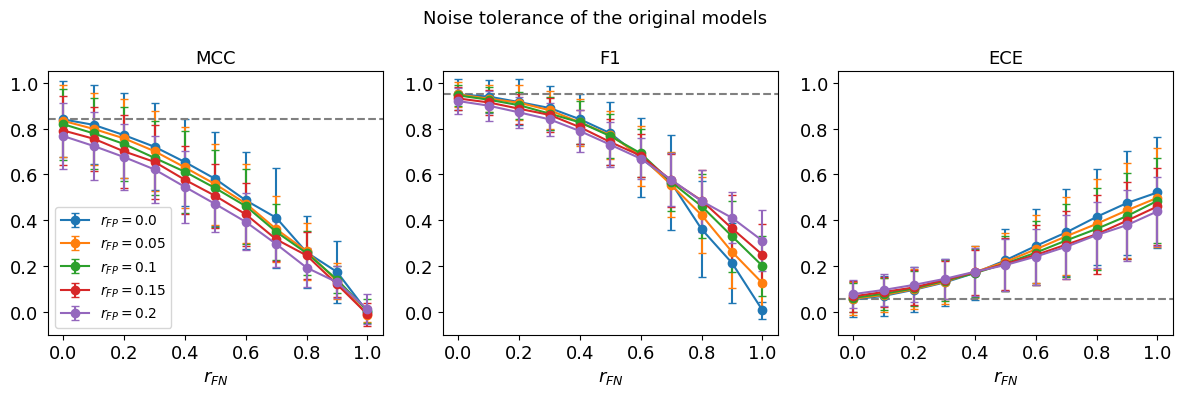

In [7]:
# Visualize the results

FONTSIZE = 13

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

metrics = [
    ("mcc", "MCC"),
    ("f1", "F1"),
    ("ece", "ECE"),
]

for ax, (metric, title) in zip(axes, metrics):

    plot_one_accur_measure(
        ax,
        metric,
        cog_remov_add_accuracies_orig_models,
        fontsize=FONTSIZE,
    )

    ax.axhline(
        y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)][metric][0],
        color="grey",
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_ylim([-0.1, 1.05])
    ax.set_title(title, fontsize=FONTSIZE)

axes[0].legend()

plt.suptitle(
    "Noise tolerance of the original models",
    fontsize=FONTSIZE,
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models.pdf",
    format="pdf",
    bbox_inches="tight",
)
plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_toler_orig_models.svg",
    format="svg",
    bbox_inches="tight",
)

plt.show()

### 3. Noise tolerance of the models trained on noisy data

In [8]:
# Create output directories for the trained models

TRAINED_MOD_DIR = "trained_models_train_val_test"
if not os.path.exists(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}"):
    os.makedirs(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}")

#### 3.1 Analyze performance of the models on the high noise range [min_fp, max_fp], [min_fn, max_fn]

Processing noise types:   0%|                                                                                            | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|████████████████████████████                                                        | 1/3 [00:03<00:06,  3.36s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|████████████████████████████████████████████████████████                            | 2/3 [00:06<00:03,  3.40s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:09<00:00,  3.23s/it]


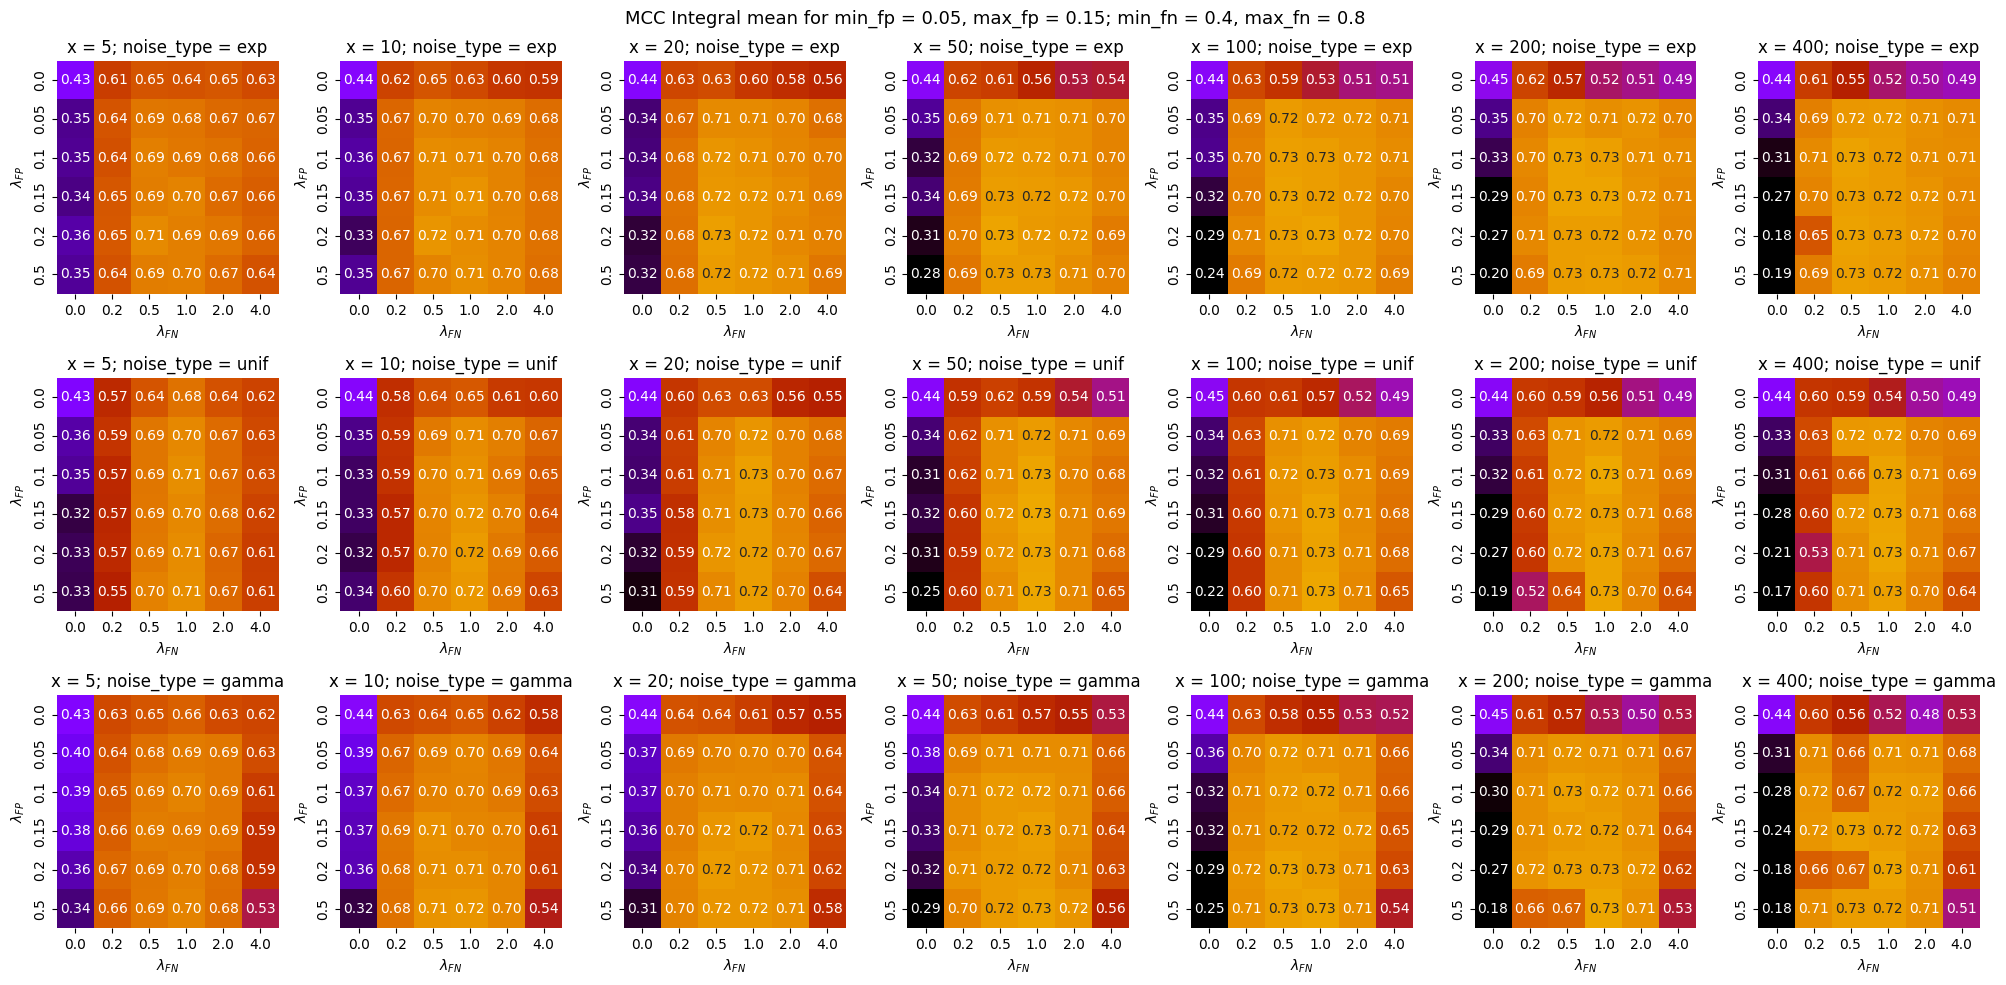

In [10]:
# Find the integrals of the MCC curves calculated for models trained on diffrent noise ranges and fisualize the result

from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, fp_curve_areas_one_model, fp_fn_surface_integral, plot_model_groups_surf_int

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100, 200, 400]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_mcc_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'mcc'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)      
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.3, vmax=0.8, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"MCC Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/mcc_integral_actoss_noise.svg", format="svg", bbox_inches='tight') #<-------save as pdf
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/mcc_integral_actoss_noise.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf

Processing noise types:   0%|                                                                                            | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|████████████████████████████                                                        | 1/3 [00:03<00:07,  3.60s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|████████████████████████████████████████████████████████                            | 2/3 [00:07<00:04,  4.02s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:12<00:00,  4.31s/it]


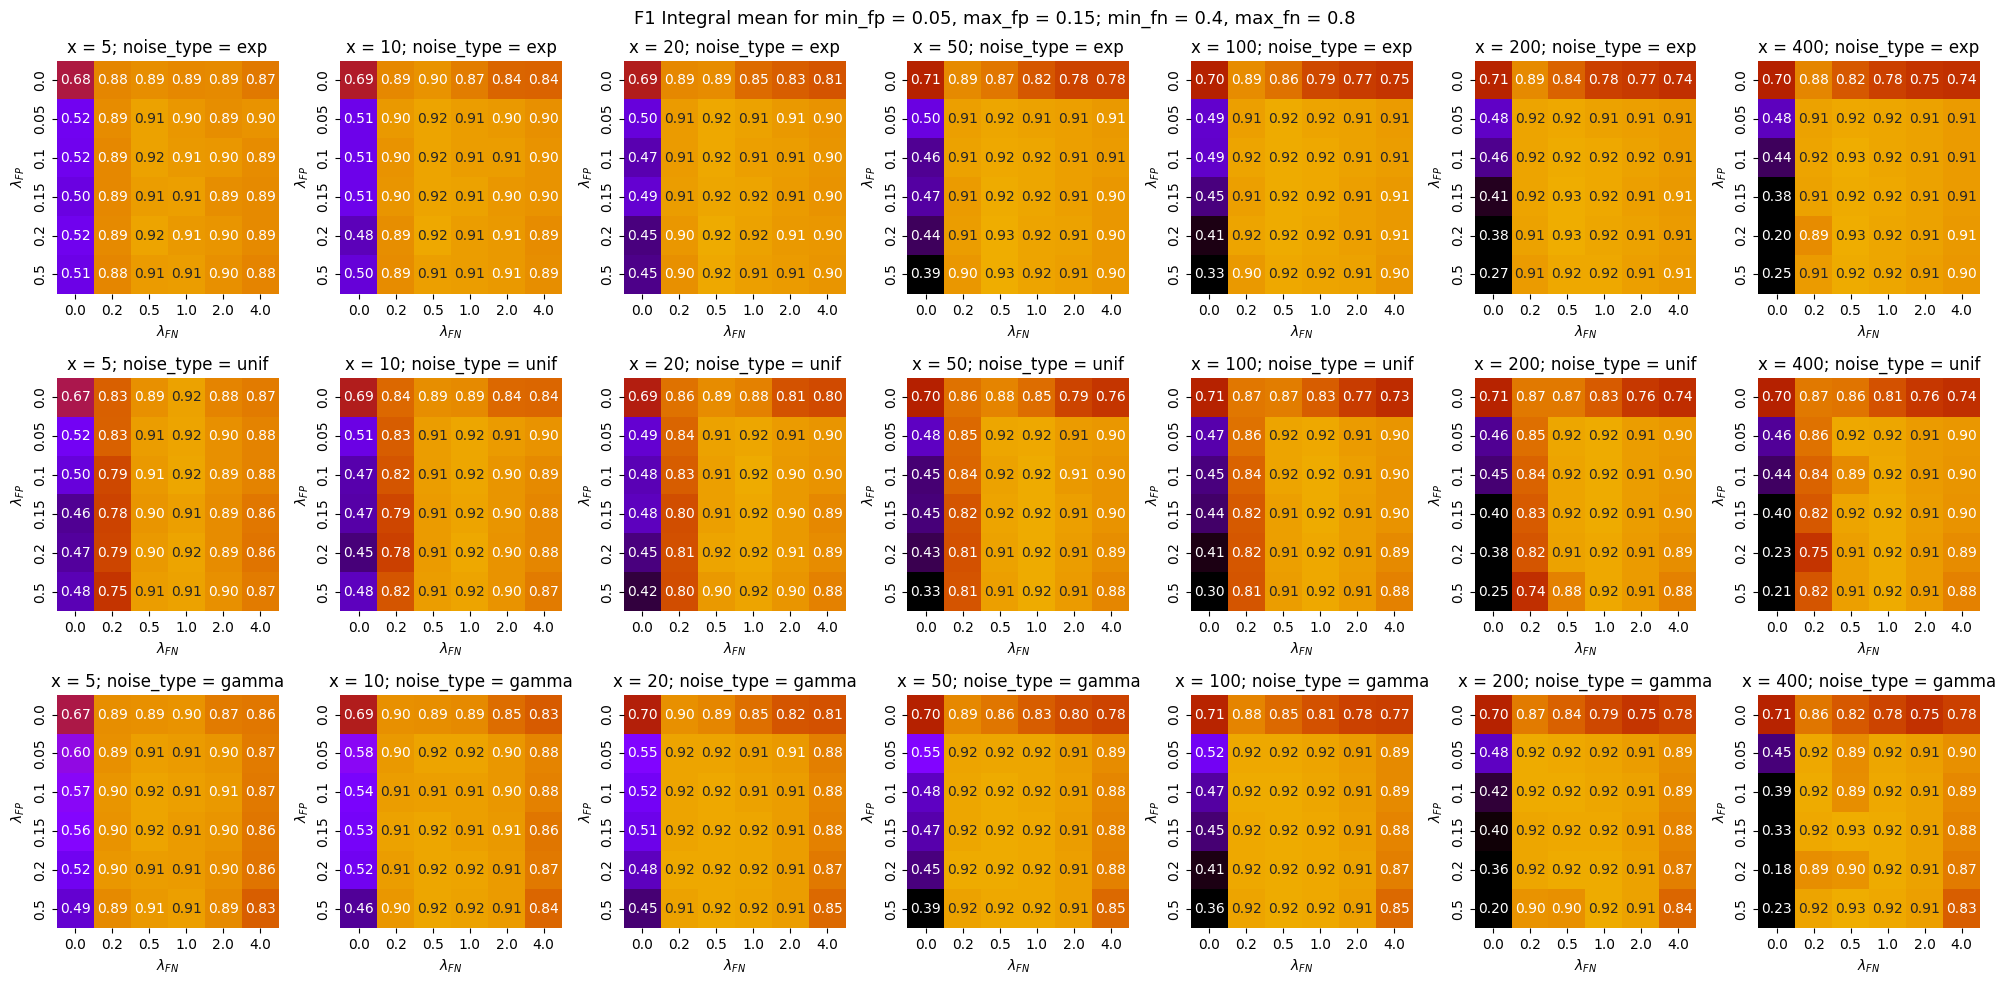

In [11]:
# Find the integrals of the F1 curves calculated for models trained on diffrent noise ranges and fisualize the result

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100, 200, 400]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_f1_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            print("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'f1'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)      
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.4, vmax=1.0, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"F1 Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/f1_integral_actoss_noise.svg", format="svg", bbox_inches='tight') #<-------save as pdf
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/f1_integral_actoss_noise.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf

Processing noise types:   0%|                                                                                            | 0/3 [00:00<?, ?it/s]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  33%|████████████████████████████                                                        | 1/3 [00:03<00:06,  3.38s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types:  67%|████████████████████████████████████████████████████████                            | 2/3 [00:07<00:03,  3.74s/it]

Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...
Loading the existing dict...


Processing noise types: 100%|████████████████████████████████████████████████████████████████████████████████████| 3/3 [00:11<00:00,  3.92s/it]


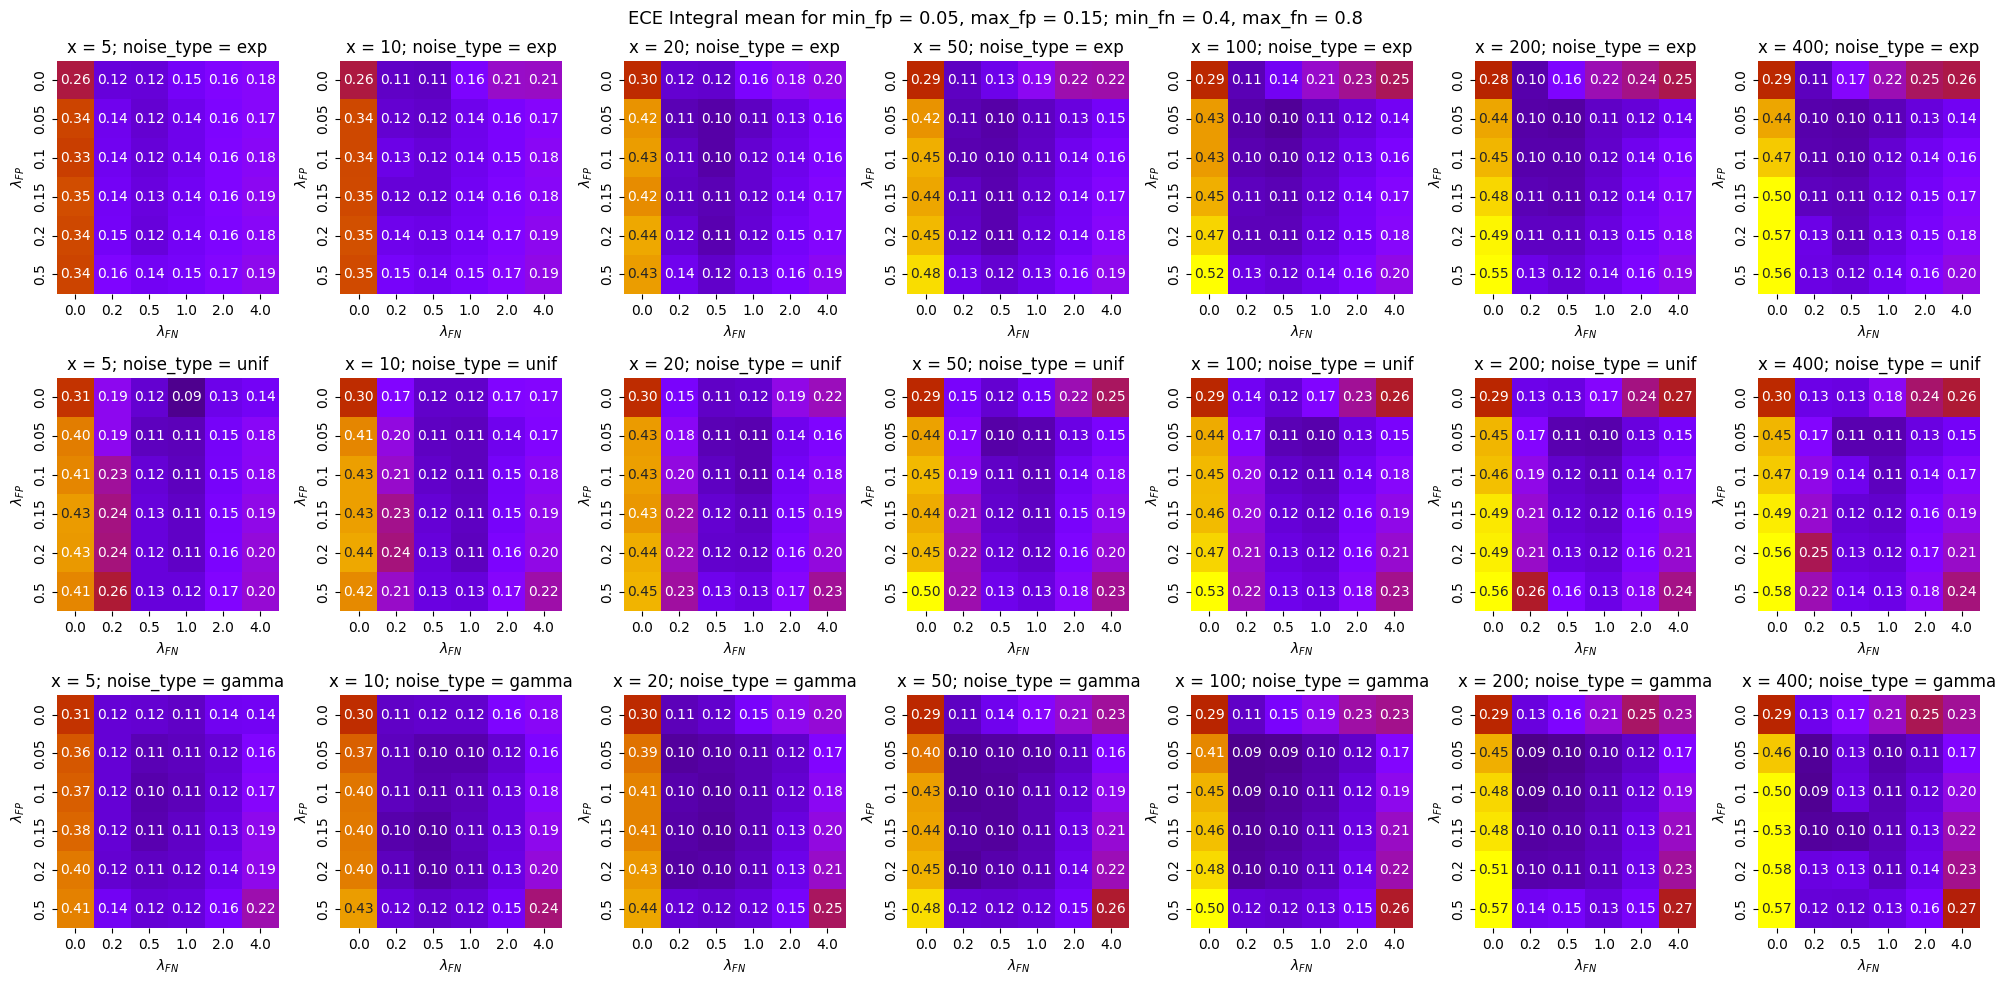

In [12]:
# Find the integrals of the ECE curves calculated for models trained on diffrent noise ranges and fisualize the result

# Specify the noise range for the test data
fn_rate_arr = [0.0, 0.2, 0.5, 1.0, 2.0, 4.0]
fp_rate_arr = [0.0, 0.05, 0.1, 0.15, 0.2, 0.5]
mean_rem_add_rates_tuples = [(add, rem) for add in fp_rate_arr for rem in fn_rate_arr]

# Specify the min and max noise ranges for the test data (the ranges for which the integrals will be calculated)
min_fn = 0.4
max_fn = 0.8

min_fp = 0.05
max_fp = 0.15

# Specify the paraters of the models trained on noise augmented data
x_range = [5, 10, 20, 50, 100, 200, 400]
noise_type_range = ["exp", "unif", "gamma"]

# Calculate the integrals for each trained model and visualize the result
fig, axes = plt.subplots(len(noise_type_range), len(x_range), figsize=(20,10))
for i, noise_type in enumerate(tqdm(noise_type_range, desc="Processing noise types")):
    for j, x in enumerate(x_range):
        ax = axes[i][j]
        filename_curve_dict = f"surf_area_ece_integrals_min_fp_{min_fp}_max_fp_{max_fp}_min_fn_{min_fn}_max_fn_{max_fn}_noise_type_{noise_type}_x_{x}.pkl" 
        filepath = f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename_curve_dict}"

        if os.path.exists(filepath):
            dprint("Loading the existing dict...")
            one_accur_dict = joblib.load(filepath)
        else:
            one_accur_dict = defaultdict(list)
            for fp_fn_tuple in mean_rem_add_rates_tuples:
                # Load the model
                filename = f"trained_models_fp_{fp_fn_tuple[0]}_fn_{fp_fn_tuple[1]}_noise_type_{noise_type}_x_{x}.pkl"
                loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
                cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, min_fp = min_fp, min_fn = min_fn, max_fp = max_fp, max_fn = max_fn, test_or_val = "val")
    
                # Find the FP curves integrals on range [max_fp, max_fn]
                metric = 'ece'
                fp_surface_integral = fp_fn_surface_integral(metric, min_fp, max_fp, min_fn, max_fn, cog_remov_add_accuracies)#fp_curve_areas_one_model(metric, max_fp, max_fn, cog_remov_add_accuracies)      
                one_accur_dict[fp_fn_tuple] = fp_surface_integral

            joblib.dump(one_accur_dict, filepath)
            print("Saving the dict...")

        plot_model_groups_surf_int(one_accur_dict, ax, vmin=0.05, vmax=0.5, cmap="gnuplot")
        ax.set_title(f"x = {x}; noise_type = {noise_type}")
        ax.set_xlabel(r"$\lambda_{FN}$")
        ax.set_ylabel(r"$\lambda_{FP}$")

plt.suptitle(rf"ECE Integral mean for min_fp = {min_fp}, max_fp = {max_fp}; min_fn = {min_fn}, max_fn = {max_fn}", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/ece_integral_actoss_noise.svg", format="svg", bbox_inches='tight') #<-------save as pdf
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/ece_integral_actoss_noise.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf

#### 3.2  Visualize the performance improvement for the chosen model

In [9]:
import joblib
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline

In [10]:
# Choose a model
x_noisy_samples = 100
fp_rate_mean = 0.1
fn_rate_mean = 0.5
noise_type = "unif"

# Load a pre-trained model
filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"
loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")

/home/a/an-koldaeva/local/python3.11/lib/python3.11/pickle.py:1718: UserWarning: [15:31:11] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)
/flash/SzollosiU/anzhelika-koldaeva/gene-context/mlm/pytorch_3.11/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.7.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainab

In [11]:
# Calculate accuracy metrics of the chosen model across different noise ranges

from utils.utils_ancestral_predict import  eval_trained_models_on_noisy_data
cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test")

In [21]:
allowed_fp = {0.0, 0.1, 0.2}

cog_remov_add_accuracies_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies.items()
    if k[1] in allowed_fp
}

cog_remov_add_accuracies_orig_models_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models.items()
    if k[1] in allowed_fp
}

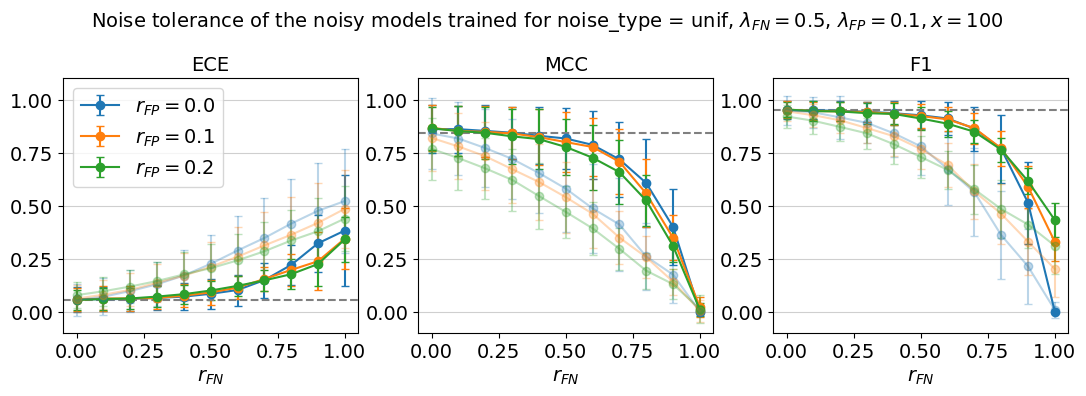

In [29]:
import matplotlib.pyplot as plt
import numpy as np

FONTSIZE=14

fig, axes = plt.subplots(1,3, figsize=(10.8, 4))  #16, 4.5

plt.subplot(1, 3, 1)
plot_one_accur_measure(axes[0], "ece", cog_remov_add_accuracies_filtered)
axes[0].legend(fontsize=FONTSIZE)
plot_one_accur_measure(axes[0], "ece", cog_remov_add_accuracies_orig_models_filtered, alpha=0.3, fontsize = FONTSIZE)
axes[0].axhline(y=cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)]['ece'][0], color='grey', linestyle='--', linewidth=1.5)
axes[0].set_ylim([-0.1,1.1])
axes[0].set_title("ECE", fontsize=FONTSIZE)
axes[0].grid(axis="y", alpha=0.6)


plt.subplot(1, 3, 2)
plot_one_accur_measure(axes[1], "mcc", cog_remov_add_accuracies_filtered)
plot_one_accur_measure(axes[1], "mcc", cog_remov_add_accuracies_orig_models_filtered, alpha=0.3, fontsize = FONTSIZE)
axes[1].axhline(y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)]['mcc'][0], color='grey', linestyle='--', linewidth=1.5)
axes[1].set_ylim([-0.1,1.1])
axes[1].set_title("MCC", fontsize=FONTSIZE)
axes[1].grid(axis="y", alpha=0.6)

plt.subplot(1, 3, 3)
plot_one_accur_measure(axes[2], "f1", cog_remov_add_accuracies_filtered)
plot_one_accur_measure(axes[2], "f1", cog_remov_add_accuracies_orig_models_filtered, alpha=0.3, fontsize = FONTSIZE)
axes[2].axhline(y=cog_remov_add_accuracies_orig_models_filtered[(0.0, 0.0)]['f1'][0], color='grey', linestyle='--', linewidth=1.5)
axes[2].set_ylim([-0.1,1.1])
axes[2].set_title("F1", fontsize=FONTSIZE)
axes[2].grid(axis="y", alpha=0.6)

plt.suptitle(f"Noise tolerance of the noisy models trained for noise_type = {noise_type}, $\lambda_{{FN}} = {fn_rate_mean}$, $\lambda_{{FP}} = {fp_rate_mean}, x = {x_noisy_samples}$", fontsize=FONTSIZE)
plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}.svg", format="svg", bbox_inches='tight')
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}.pdf", format="pdf", bbox_inches='tight') 

In [30]:
f"{OUTPUT_DIRECTORY}/plots/noise_toler_noisy_model_FP_{fp_rate_mean}_FN_{fn_rate_mean}_x_{x_noisy_samples}.svg"

'../data_aerob/outputs/phylum/plots/noise_toler_noisy_model_FP_0.1_FN_0.5_x_100.svg'

In [13]:
# cog_remov_add_accuracies

#### 3.2  Visualize the performance improvement for the chosen model across evo distancies

In [6]:
import pandas as pd
from Bio import Phylo

TIME_UNIT_FACTOR = 1.0   # 1000 if branch lengths are in Ga
TREE_FILE = "../ancestral_data/C65.tree"
GENOMES_INFO = "../ancestral_data/GenomesInfo.csv"
BAC_TSV = "../data_preparation/gtdb_files/bac120_metadata_r202.tsv"
ARC_TSV = "../data_preparation/gtdb_files/ar122_metadata_r202.tsv"

RANKS = ["domain", "phylum", "class", "order", "family", "genus", "species"]
RANK_IDX = {r: i for i, r in enumerate(RANKS)} 

In [7]:
LABEL_MAP = {"anaerobe": 0, "aerobe": 1} 

In [8]:
from utils.utils_ancestral_predict import norm

# ---- 1. Load the tree, build parent links and node ages ----
tree = Phylo.read(TREE_FILE, "newick")

parent = {}   # id(child clade) -> parent clade
age = {}      # id(clade) -> age (Ma before present)
for clade in tree.find_clades(order="postorder"):
    if clade.is_terminal():
        age[id(clade)] = 0.0
    else:
        age[id(clade)] = float(np.mean([age[id(c)] + (c.branch_length or 0.0) for c in clade.clades]))
        for c in clade.clades:
            parent[id(c)] = clade

leaf_by_name = {norm(t.name): t for t in tree.get_terminals()}
print(f"Tree has {len(leaf_by_name)} tips; root age = {age[id(tree.root)] * TIME_UNIT_FACTOR:.1f} Ma")

Tree has 1007 tips; root age = 4333.2 Ma


In [9]:
from utils.utils_ancestral_predict import acc_key

# ---- 2. Map accessions -> tree tip names (GenomesInfo.csv) ----
info = pd.read_csv(GENOMES_INFO, sep=",")
print("GenomesInfo columns:", info.columns.tolist())

# Detect which column holds tip names and which holds accessions
tip_col = next(c for c in info.columns
               if info[c].astype(str).map(norm).isin(set(leaf_by_name)).mean() > 0.5)
acc_col = next(c for c in info.columns
               if info[c].astype(str).str.contains(r"GC[AF]_\d+").mean() > 0.5)
print(f"tip column = '{tip_col}', accession column = '{acc_col}'")

acc_to_tip = dict(zip(info[acc_col].astype(str).map(acc_key),
                      info[tip_col].astype(str).map(norm)))
print(f"{len(acc_to_tip)} accessions linked to tree tips")

GenomesInfo columns: ['accession', 'ShortCode', 'r202_accession', 'checkm_completeness', 'checkm_contamination', 'quality', 'genome_size', 'gc_percentage', 'gtdb_type_designation', 'gtdb_genome_representative', 'gtdb_representative', 'ncbi_taxid', 'gtdb_taxonomy', 'phylum', 'class', 'order', 'family', 'genus', 'sp', 'taxid', 'name', 'temperature', 'morphology', 'motility', 'flagellum', 'oxytolerance', 'halotolerance', 'host-associated']
tip column = 'ShortCode', accession column = 'accession'
1007 accessions linked to tree tips


In [10]:
# ---- 3. Taxonomy for tree tips and for your genomes (GTDB) ----
gtdb = pd.concat([
    pd.read_csv(BAC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
    pd.read_csv(ARC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
])
tax_by_acc = dict(zip(gtdb["accession"].map(acc_key), gtdb["gtdb_taxonomy"].str.split(";")))

# Tree tips -> taxonomy (via their accession in GenomesInfo.csv)
taxon_to_tips = {}   # (rank, taxon) -> list of tip names
n_tips_with_tax = 0
for acc, tip in acc_to_tip.items():
    tax = tax_by_acc.get(acc)
    if tax is None or tip not in leaf_by_name:
        continue
    n_tips_with_tax += 1
    for rank, taxon in zip(RANKS, tax):
        if taxon.endswith("__"):        # empty rank, e.g. 'g__'
            continue
        taxon_to_tips.setdefault((rank, taxon), []).append(tip)
print(f"{n_tips_with_tax}/{len(leaf_by_name)} tree tips have GTDB taxonomy")


# ---- 4. Place a genome on the tree by its lowest rank present in the tree ----
# _clade_cache = {}



997/1007 tree tips have GTDB taxonomy


In [11]:
# # ---- 4. Place a genome on the tree by its lowest rank present in the tree ----
# _clade_cache = {}

# def place(acc, ranks):
#     """Returns (clade, rank) for a genome, or (None, None) if even its domain isn't in the tree."""
#     tax = tax_by_acc.get(acc_key(acc))
#     if tax is None:
#         return None, None
#     for rank, taxon in reversed(list(zip(ranks, tax))):     # species -> genus -> ... -> domain
#         tips = taxon_to_tips.get((rank, taxon))
#         if tips:
#             key = (rank, taxon)
#             if key not in _clade_cache:
#                 _clade_cache[key] = tree.common_ancestor([leaf_by_name[t] for t in tips])
#             return _clade_cache[key], rank
#     return None, None


# # ---- 5. Distance from each test genome to its nearest training relative ----


In [12]:
from utils.utils_ancestral_predict import read_acc
# All accessions in the dataset (every genome appears in train, val or test of any split)
_base = f"../{DATA_DIRECTORY}/input_data_train_val_test/class"
ALL_ACC = sorted(set(
    read_acc(f"{_base}/train_annot_class_split_0")
    + read_acc(f"{_base}/val_annot_class_split_0")
    + read_acc(f"{_base}/test_annot_class_split_0")
))
phylum_of = {a: tax_by_acc[acc_key(a)][1] for a in ALL_ACC if acc_key(a) in tax_by_acc}

In [13]:
import joblib
from tqdm import tqdm
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline
from utils.utils_ancestral_predict import eval_trained_models_on_noisy_data, plot_one_accur_measure

def train_and_evaluate_orig_models(all_splits_dict):
    # Train and save models for each data split
    trained_models = {}
    for split_id in all_splits_dict.keys():#tqdm(all_splits_dict.keys(), desc="Training splits"):
        X_val_train = all_splits_dict[split_id]["X_train"]
        y_label_train = all_splits_dict[split_id]["y_train"]
    
        pipe = make_pipeline(
            make_pipeline(XGBClassifier(n_jobs=THREADS if DEVICE == "cpu" else None, tree_method="gpu_hist" if DEVICE == "cpu" else "hist"))
        )
        pipe.fit(X_val_train.cpu(), y_label_train.cpu())
        trained_models[split_id] = pipe
    cog_remov_add_accuracies_orig_models = eval_trained_models_on_noisy_data(all_splits_dict, trained_models, hard_fn_flag = True, return_raw = True) 
    
    return cog_remov_add_accuracies_orig_models

In [14]:
from utils.utils_ancestral_predict import read_splits

from collections import defaultdict

tax_levels = ["random", "family", "order", "class", "phylum"]

mcc_tax_levels = defaultdict()
for tax_level in tqdm(tax_levels, desc="Tax levels"):
    all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    cog_remov_add_accuracies_orig_models = train_and_evaluate_orig_models(all_splits_dict)
    mcc_tax_levels[tax_level] = cog_remov_add_accuracies_orig_models#[(fn, fp)]['mcc']

Tax levels: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [09:53<00:00, 118.79s/it]


In [15]:
from utils.utils_ancestral_predict import  eval_trained_models_on_noisy_data

# Choose a model
TRAINED_MOD_DIR = "trained_models_train_val_test"
x_noisy_samples = 100
fp_rate_mean = 0.1
fn_rate_mean = 0.5
noise_type = "unif"
filename = f"trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x_noisy_samples}.pkl"

mcc_tax_levels_noise_rob_models = defaultdict()
for tax_level in tqdm(tax_levels, desc="Tax levels"):
    all_splits_dict = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    OUTPUT_DIRECTORY = f"../{DATA_DIRECTORY}/outputs/{tax_level}"
    loaded_models_dict = joblib.load(f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")
    cog_remov_add_accuracies = eval_trained_models_on_noisy_data(all_splits_dict, loaded_models_dict, hard_fn_flag = True, test_or_val = "test", return_raw = True)
    mcc_tax_levels_noise_rob_models[tax_level] = cog_remov_add_accuracies

Tax levels:  80%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                | 4/5 [07:07<01:48, 108.65s/it]/home/a/an-koldaeva/local/python3.11/lib/python3.11/pickle.py:1718: UserWarning: [15:24:58] WARNING: /__w/xgboost/xgboost/src/collective/../data/../common/error_msg.h:83: If you are loading a serialized model (like pickle in Python, RDS in R) or
configuration generated by an older version of XGBoost, please export the model by calling
`Booster.save_model` from that version first, then load it back in current version. See:

    https://xgboost.readthedocs.io/en/stable/tutorials/saving_model.html

for more details about differences between saving model and serializing.

  setstate(state)
/flash/SzollosiU/anzhelika-koldaeva/gene-context/mlm/pytorch_3.11/lib/python3.11/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1

In [16]:
# cog_remov_add_accuracies

In [17]:
from tqdm import tqdm
from utils.utils_ancestral_predict import  nearest_train_times

per_split_time = {}   # level -> {split_id: median distance in Ma}
per_split_n = {}
#for lvl in LEVELS:
for tax_level in tqdm(tax_levels, desc="Tax levels"):     #tax_levels
    splits = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    per_split_time[tax_level] = {}
    per_split_n[tax_level] = {}
    for split_id, d in splits.items():
        times, missing = nearest_train_times(d["acc_train"], d["acc_test"], RANK_IDX, RANKS, tax_by_acc, taxon_to_tips, acc_key, tree, leaf_by_name, age, parent, coarsest_rank="genus")
        per_split_time[tax_level][split_id] = np.min(times) #or median
        per_split_n[tax_level][split_id] = (len(times), missing, len(d["acc_test"]))
    vals = list(per_split_time[tax_level].values())
    print(f"{tax_level:>7}: metric over {len(vals)} splits = {np.median(vals):6.0f} Ma "
          f"(range {np.min(vals):.0f} to {np.max(vals):.0f})")

#pd.DataFrame(per_split_time).to_csv("divergence_time_per_split.csv")

Tax levels:  20%|████████████████████████████████▊                                                                                                                                   | 1/5 [01:01<04:05, 61.38s/it]

 random: metric over 30 splits =      0 Ma (range 0 to 0)


Tax levels:  40%|█████████████████████████████████████████████████████████████████▌                                                                                                  | 2/5 [02:05<03:08, 62.71s/it]

 family: metric over 30 splits =    962 Ma (range 724 to 1438)


Tax levels:  60%|██████████████████████████████████████████████████████████████████████████████████████████████████▍                                                                 | 3/5 [03:07<02:05, 62.50s/it]

  order: metric over 30 splits =   1168 Ma (range 724 to 2061)


Tax levels:  80%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                                | 4/5 [04:10<01:02, 62.86s/it]

  class: metric over 30 splits =   3286 Ma (range 2890 to 4619)


Tax levels: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [04:55<00:00, 59.08s/it]

 phylum: metric over 30 splits =   5118 Ma (range 4619 to 5753)


In [18]:
per_split_time_mean_stds = defaultdict()

for taxa in per_split_time.keys():
    mn = np.mean(list(per_split_time[taxa].values()))
    std = np.std(list(per_split_time[taxa].values()))
    per_split_time_mean_stds[taxa] = (mn, std)

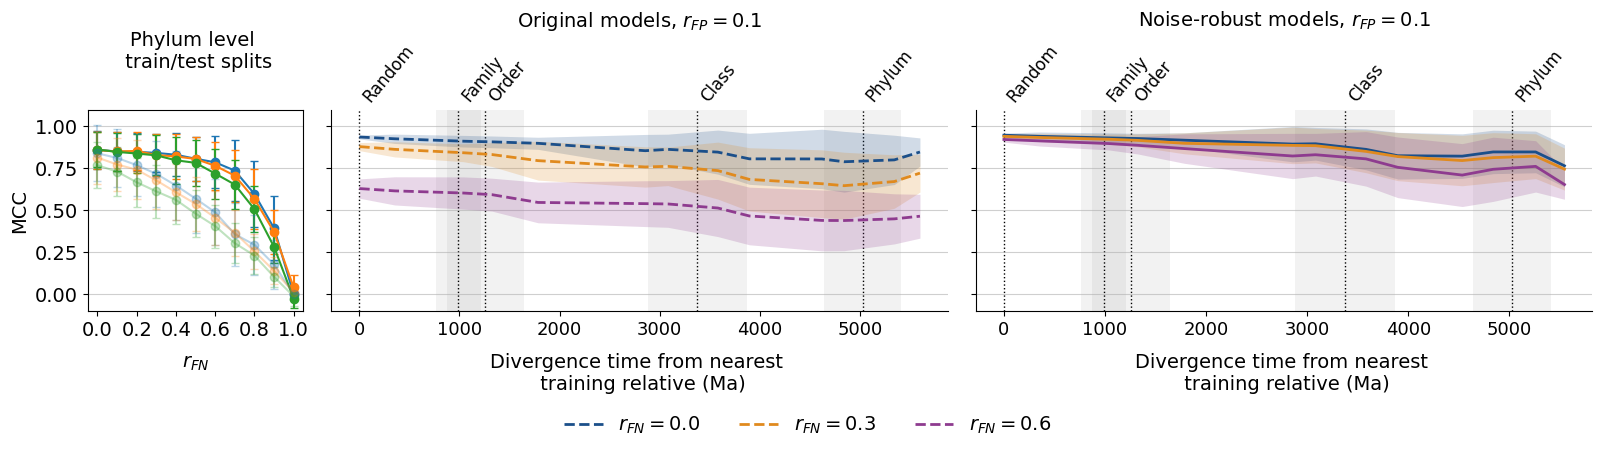

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from utils.utils_ancestral_predict import rolling_mean_std_curve

tax_levels = ["random", "family", "order", "class", "phylum"]
colors = ["#1B4F8A", "#E08A1E", "#8E3B8F"]  # ["tab:blue", "tab:orange", "tab:green"]

fp = 0.1
fn_range = [0.0, 0.3, 0.6]

FONTSIZE = 14

fig, axes = plt.subplots(
    1, 3, figsize=(16, 4.5), sharey=True,
    gridspec_kw={"width_ratios": [0.35, 1, 1]}
)
# ---------------------------------------------------------------
# Corridors (mean ± std of divergence time per taxonomic level),
# drawn ONCE, outside the fn loop
# ---------------------------------------------------------------
tick_pos, tick_lab = [], []
for tax_level in tax_levels:
    t = np.asarray(list(per_split_time[tax_level].values()), dtype=float)
    t = t[t <= 7000]
    mu, sd = t.mean(), t.std()

    for ax in [axes[1], axes[2]]:
        ax.axvspan(mu - sd, mu + sd, color="grey",
                   alpha=0.1, linewidth=0, zorder=0)
        ax.axvline(mu, color="black", linestyle=":",
                   linewidth=1, zorder=1)

    tick_pos.append(mu)
    tick_lab.append(tax_level.capitalize())

# ---------------------------------------------------------------
# Curves
# ---------------------------------------------------------------
for i, fn in enumerate(fn_range):
    all_points_x = []
    all_points_y = []
    all_points_x_noise_rob_mod = []
    all_points_y_noise_rob_mod = []

    for tax_level in tax_levels:
        # orig model
        all_points_x += list(per_split_time[tax_level].values())
        all_points_y += list(mcc_tax_levels[tax_level][(fn, fp)]['mcc'])

        # noise-robust model
        n = len(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['mcc'])
        all_points_x_noise_rob_mod += list(per_split_time[tax_level].values())[:n]
        all_points_y_noise_rob_mod += list(mcc_tax_levels_noise_rob_models[tax_level][(fn, fp)]['mcc'])

    # orig model filtered
    x_arr = np.asarray(all_points_x, dtype=float)
    y_arr = np.asarray(all_points_y, dtype=float)
    mask = x_arr <= 7000
    all_points_x = x_arr[mask]
    all_points_y = y_arr[mask]

    # noise-robust model filtered
    x_arr = np.asarray(all_points_x_noise_rob_mod, dtype=float)
    y_arr = np.asarray(all_points_y_noise_rob_mod, dtype=float)
    mask = x_arr <= 7000
    all_points_x_noise_rob_mod = x_arr[mask]
    all_points_y_noise_rob_mod = y_arr[mask]

    x_mean, y_mean, y_std = rolling_mean_std_curve(
        all_points_x, all_points_y, window=1000
    )
    x_mean_nr, y_mean_nr, y_std_nr = rolling_mean_std_curve(
        all_points_x_noise_rob_mod, all_points_y_noise_rob_mod, window=1000
    )

    label = fr"$r_{{FN}} = {fn}$"

    # Left: original models
    axes[1].fill_between(x_mean,
                         np.clip(y_mean - y_std, 0, 1),
                         np.clip(y_mean + y_std, 0, 1),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[1].plot(x_mean, y_mean, c=colors[i], linestyle="--",
                 linewidth=2, label=label, zorder=3)

    # Right: noise-robust models
    axes[2].fill_between(x_mean_nr,
                         np.clip(y_mean_nr - y_std_nr, 0, 1),
                         np.clip(y_mean_nr + y_std_nr, 0, 1),
                         color=colors[i], alpha=0.2, linewidth=0, zorder=2)
    axes[2].plot(x_mean_nr, y_mean_nr, c=colors[i], linestyle="-",
                 linewidth=2, label=label, zorder=3)


#plt.subplot(1, 3, 2)
cog_remov_add_accuracies_mn_std = {}
cog_remov_add_accuracies_orig_models_mn_std = {}
for rates in cog_remov_add_accuracies.keys():
    cog_remov_add_accuracies_mn_std[rates] = {}
    cog_remov_add_accuracies_orig_models_mn_std[rates] = {}
    for metric in cog_remov_add_accuracies[rates].keys():
        cog_remov_add_accuracies_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies[rates][metric] ), np.std(cog_remov_add_accuracies[rates][metric] ))
        cog_remov_add_accuracies_orig_models_mn_std[rates][metric] = (np.mean(cog_remov_add_accuracies_orig_models[rates][metric] ), np.std(cog_remov_add_accuracies_orig_models[rates][metric] ))

allowed_fp = {0.0, 0.1, 0.2}



cog_remov_add_accuracies_orig_models_mn_std_filtered = {
    k: v
    for k, v in cog_remov_add_accuracies_orig_models_mn_std.items()
    if k[1] in allowed_fp
}

plot_one_accur_measure(axes[0], "mcc", cog_remov_add_accuracies_mn_std_filtered)
plot_one_accur_measure(axes[0], "mcc", cog_remov_add_accuracies_orig_models_mn_std_filtered, alpha=0.3, fontsize = FONTSIZE)
# axes[2].axhline(y=cog_remov_add_accuracies_orig_models[(0.0, 0.0)]['mcc'][0], color='grey', linestyle='--', linewidth=1.5)
# axes[2].set_ylim([-0.1,1.05])
# axes[2].set_title("MCC", fontsize=FONTSIZE)


# ---------------------------------------------------------------
# Axes styling
# ---------------------------------------------------------------
for ax in [axes[1], axes[2]]:
    # second x-axis layer with taxonomic level names
    sec = ax.secondary_xaxis("top")
    sec.set_xticks(tick_pos)
    sec.set_xticklabels(tick_lab, rotation=50, ha="left")
    sec.tick_params(labelsize=12, length=0)
    sec.spines["top"].set_visible(False)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.6)
    ax.tick_params(labelsize=13)
    ax.set_ylim([-0.1, 1.1])
    ax.set_xlabel("Divergence time from nearest \n training relative (Ma)", fontsize=14, labelpad=10)

axes[1].set_title(fr"Original models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[2].set_title(fr"Noise-robust models, $r_{{FP}} = {fp}$", fontsize=14, pad=10)
axes[0].set_ylabel("MCC", fontsize=14)

axes[0].grid(axis="y", alpha=0.6)
axes[0].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1])
axes[0].set_title("Phylum level \n train/test splits", fontsize=14, pad=30)
axes[0].set_xlabel(r"$r_{FN}$", fontsize=14, labelpad=10)

# one shared legend instead of one per panel
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3,
           frameon=False, fontsize=14, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.svg",
    format="svg",
    bbox_inches="tight",
)

plt.savefig(
    f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

In [27]:
f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.svg"

'../data_aerob/outputs/phylum/plots/noise_in_evo_dist_fp_0.1.svg'

In [20]:
f"{OUTPUT_DIRECTORY}/plots/noise_in_evo_dist_fp_{fp}.svg"

'../data_aerob/outputs/phylum/plots/noise_in_evo_dist_fp_0.1.svg'

In [21]:
cog_remov_add_accuracies.keys()

dict_keys([(0.0, 0.0), (0.0, 0.05), (0.0, 0.1), (0.0, 0.15), (0.0, 0.2), (0.1, 0.0), (0.1, 0.05), (0.1, 0.1), (0.1, 0.15), (0.1, 0.2), (0.2, 0.0), (0.2, 0.05), (0.2, 0.1), (0.2, 0.15), (0.2, 0.2), (0.3, 0.0), (0.3, 0.05), (0.3, 0.1), (0.3, 0.15), (0.3, 0.2), (0.4, 0.0), (0.4, 0.05), (0.4, 0.1), (0.4, 0.15), (0.4, 0.2), (0.5, 0.0), (0.5, 0.05), (0.5, 0.1), (0.5, 0.15), (0.5, 0.2), (0.6, 0.0), (0.6, 0.05), (0.6, 0.1), (0.6, 0.15), (0.6, 0.2), (0.7, 0.0), (0.7, 0.05), (0.7, 0.1), (0.7, 0.15), (0.7, 0.2), (0.8, 0.0), (0.8, 0.05), (0.8, 0.1), (0.8, 0.15), (0.8, 0.2), (0.9, 0.0), (0.9, 0.05), (0.9, 0.1), (0.9, 0.15), (0.9, 0.2), (1.0, 0.0), (1.0, 0.05), (1.0, 0.1), (1.0, 0.15), (1.0, 0.2)])

### 4. Optional: Visualize noisy data

In [17]:
# Merge the train and test data
X = torch.cat((torch.cat((X_val_train, X_val_val), dim=0), X_val_test), dim=0)
y = torch.cat((torch.cat((y_label_train, y_label_val), dim=0), y_label_test), dim=0)
taxa_group_names = (
    list(taxa_group_names_train)
    + list(taxa_group_names_val)
    + list(taxa_group_names_test)
)
len(taxa_group_names)

3184

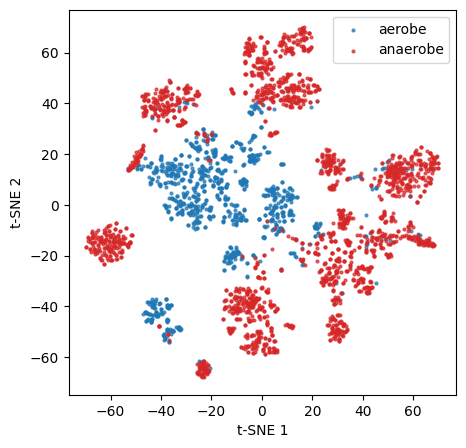

In [28]:
from sklearn.manifold import TSNE

plt.figure(figsize=(5,5))

X_np = X.detach().cpu().numpy()
y_np = y.detach().cpu().numpy()

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_emb = tsne.fit_transform(X_np)

# class 0
idx0 = y_np == 0
plt.scatter(
    X_emb[idx0, 0],
    X_emb[idx0, 1],
    color="tab:blue",
    label="aerobe",
    alpha=0.7,
    s=4
)

# class 1
idx1 = y_np == 1
plt.scatter(
    X_emb[idx1, 0],
    X_emb[idx1, 1],
    color="tab:red",
    label="anaerobe",
    alpha=0.7,
    s = 4
)

plt.legend()
#plt.title("t-SNE colored by binary class")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")

plt.show()

In [19]:
from utils.utils_ancestral_predict import sample_exp, sample_unif, sample_gamma, augment_data_with_noise

In [30]:
def apply_noise(genome, fp_rate=0.2, fn_rate=0.5):
    # work in float for Poisson
    genome = genome.float()
    genome_noisy = genome.clone()

    # False negatives 
    # sample how many counts to remove
    losses = torch.poisson(genome * fn_rate)
    genome_noisy = torch.clamp(genome_noisy - losses, min=0.0)

    # False positives 
    fp_add = torch.zeros_like(genome_noisy)

    # only add to true zeros
    zero_mask = genome == 0
    num_zeros = int(zero_mask.sum())

    if num_zeros > 0:
        fp_samples = torch.poisson(
            torch.full(
                (num_zeros,),
                fp_rate,
                dtype=torch.float32,
                device=genome.device
            )
        )
        fp_add[zero_mask] = fp_samples

    genome_noisy = genome_noisy + fp_add

    return genome_noisy

In [31]:
def augment_data_with_noise(X_val_train, y_label_train, taxa_group_names, n_clones, mean_fp, mean_fn, noise_type=None, filename=None):
    # Start with the original data as lists
    X_augmented_list = [X_val_train]
    y_augmented_list = [y_label_train]
    taxa_group_names_augmented = taxa_group_names[:]

    if n_clones == 0:
        return X_val_train.clone(), y_label_train.clone(), taxa_group_names_augmented

    n_rows, _ = X_val_train.shape
    for i in range(n_rows):   
        genome = X_val_train[i]
        label = y_label_train[i]
        taxa = taxa_group_names[i]
        for _ in range(n_clones):

            # Sample FP/FN rates based on noise_type
            if noise_type == "exp":
                fp_rate_sampled = sample_exp(mean_fp)
                fn_rate_sampled = sample_exp(mean_fn)
            elif noise_type == "gamma":  
                fp_rate_sampled = sample_gamma(mean_fp)
                fn_rate_sampled = sample_gamma(mean_fn)
            elif noise_type == "unif":     
                fp_rate_sampled = sample_unif(mean_fp)
                fn_rate_sampled = sample_unif(mean_fn) 
            else:
                print(f"Incorrect noise type!")

            # Apply noise
            genome_noisy = apply_noise(genome, fp_rate=fp_rate_sampled, fn_rate=fn_rate_sampled)
            
            # Append to lists
            X_augmented_list.append(genome_noisy.unsqueeze(0))
            y_augmented_list.append(label.unsqueeze(0))
            taxa_group_names_augmented.append(taxa)
           # print(len(taxa_group_names_augmented))

    # Stack / concatenate once at the end
    X_augmented = torch.cat(X_augmented_list, dim=0)
    y_augmented = torch.cat(y_augmented_list, dim=0)


    # Shuffle the augmented dataset
    # idx = torch.randperm(len(X_augmented))
    # X_augmented, y_augmented = X_augmented[idx], y_augmented[idx]

    return X_augmented, y_augmented, taxa_group_names_augmented

In [32]:
# Find tSNE projections of noise augmented data for different noise ranges

x_noisy_samples =20
fp_rate_mean =0.1
fn_rate_mean = 0.3
noise_type = "unif"

X_augmented, y_augmented, taxa_group_names_augmented = augment_data_with_noise(X, y, taxa_group_names, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
X_np = X_augmented.detach().cpu().numpy()
y_np = y_augmented.detach().cpu().numpy()
# t-SNE 1
tsne = TSNE(n_components=2, perplexity=40, random_state=42)
X_emb_03 = tsne.fit_transform(X_np)

In [220]:
x_noisy_samples =20
fp_rate_mean =0.1
fn_rate_mean = 0.4
noise_type = "unif"

X_augmented, y_augmented, taxa_group_names_augmented = augment_data_with_noise(X, y, taxa_group_names, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
X_np = X_augmented.detach().cpu().numpy()
y_np = y_augmented.detach().cpu().numpy()
# t-SNE 1
tsne = TSNE(n_components=2, perplexity=40, random_state=42)
X_emb_04 = tsne.fit_transform(X_np)

In [222]:
x_noisy_samples =20
fp_rate_mean =0.1
fn_rate_mean = 0.5
noise_type = "unif"

X_augmented, y_augmented, taxa_group_names_augmented = augment_data_with_noise(X, y, taxa_group_names, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
X_np = X_augmented.detach().cpu().numpy()
y_np = y_augmented.detach().cpu().numpy()
# t-SNE 1
tsne = TSNE(n_components=2, perplexity=40, random_state=42)
X_emb_05 = tsne.fit_transform(X_np)

In [221]:
x_noisy_samples =20
fp_rate_mean =0.1
fn_rate_mean = 1
noise_type = "unif"

X_augmented, y_augmented, taxa_group_names_augmented = augment_data_with_noise(X, y, taxa_group_names, n_clones=x_noisy_samples, mean_fp=fp_rate_mean, mean_fn=fn_rate_mean, noise_type=noise_type)
X_np = X_augmented.detach().cpu().numpy()
y_np = y_augmented.detach().cpu().numpy()
# t-SNE 1
tsne = TSNE(n_components=2, perplexity=40, random_state=42)
X_emb_1 = tsne.fit_transform(X_np)

In [232]:
def plot_tsne_phenot_tot(X_emb):
    # class 0
    idx0 = y_np == 0
    plt.scatter(
        X_emb[idx0, 0],
        X_emb[idx0, 1],
        color="tab:blue",
        label="anaerobe",
        alpha=0.7,
        s=3
    )
    
    # class 1
    idx1 = y_np == 1
    plt.scatter(
        X_emb[idx1, 0],
        X_emb[idx1, 1],
        color="tab:red",
        label="aerobe",
        alpha=0.7,
        s = 3
    )
    
    plt.xlabel("t-SNE 1", fontsize=10)
    plt.ylabel("t-SNE 2",fontsize=10)
    plt.tick_params(axis='both', labelsize=10)

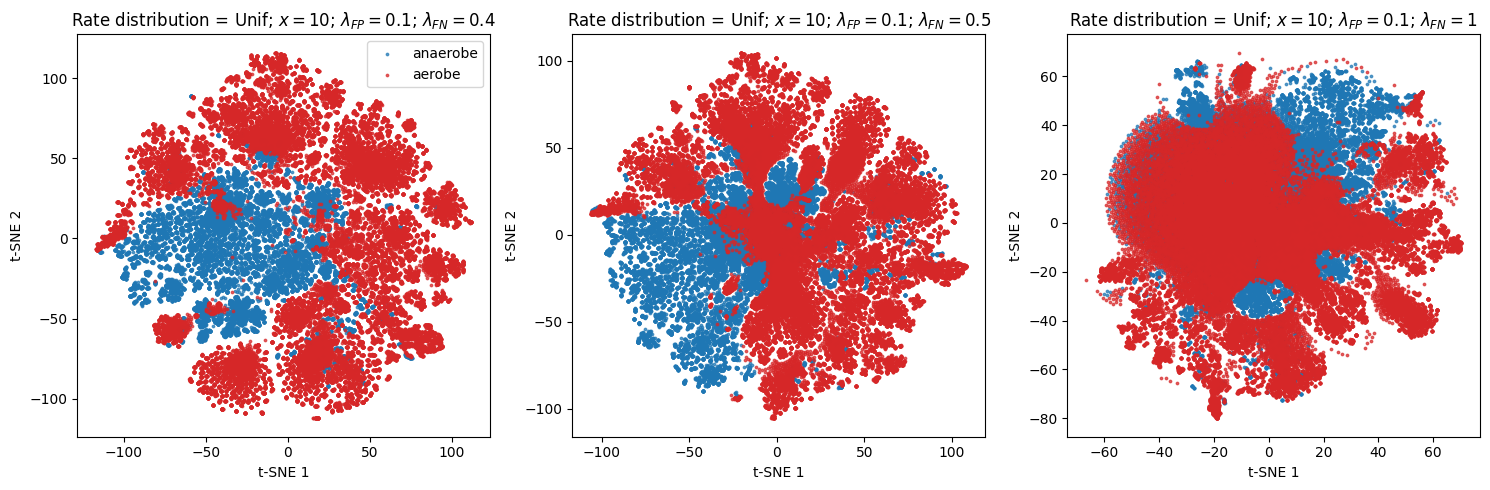

In [233]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plot_tsne_phenot_tot(X_emb_04)
plt.legend()
plt.title(rf"Rate distribution = Unif; "rf"$x = 10$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 0.4$")

plt.subplot(1,3,2)
plot_tsne_phenot_tot(X_emb_05)
plt.title(rf"Rate distribution = Unif; "rf"$x = 10$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 0.5$")

plt.subplot(1,3,3)
plot_tsne_phenot_tot(X_emb_1)
plt.title(rf"Rate distribution = Unif; "rf"$x = 10$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 1$")

plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_level_tsne.svg", format="svg", bbox_inches='tight') #<-------save as pdf
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_level_tsne.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf
plt.show()

In [234]:
def plot_tsne_pnenot_noise_vs_clean(X_emb):
    # original points (no outline)
    plt.scatter(
        X_emb[idx0 & (np.arange(len(y_np)) < N), 0],
        X_emb[idx0 & (np.arange(len(y_np)) < N), 1],
        color="tab:blue",
        alpha=0.9,
        s=3
    )
    
    plt.scatter(
        X_emb[idx1 & (np.arange(len(y_np)) < N), 0],
        X_emb[idx1 & (np.arange(len(y_np)) < N), 1],
        color="tab:red",
        alpha=0.9,
        s=3
    )
    
    #outlined points (from N onward) 
    mask_tail = np.arange(len(y_np)) >= N
    
    plt.scatter(
        X_emb[idx0 & mask_tail, 0],
        X_emb[idx0 & mask_tail, 1],
        color="tab:blue",
      #  edgecolors="black",
        linewidths=0.4,
        alpha=0.1,
        s=3,
        label="aerobe (augmented)"
    )
    
    plt.scatter(
        X_emb[idx1 & mask_tail, 0],
        X_emb[idx1 & mask_tail, 1],
        color="tab:red",
      #  edgecolors="black",
        linewidths=0.4,
        alpha=0.1,
        s=3,
        label="anaerobe (augmented)"
    )

    plt.xlabel("t-SNE 1", fontsize=10)
    plt.ylabel("t-SNE 2",fontsize=10)
    plt.tick_params(axis='both', labelsize=10)

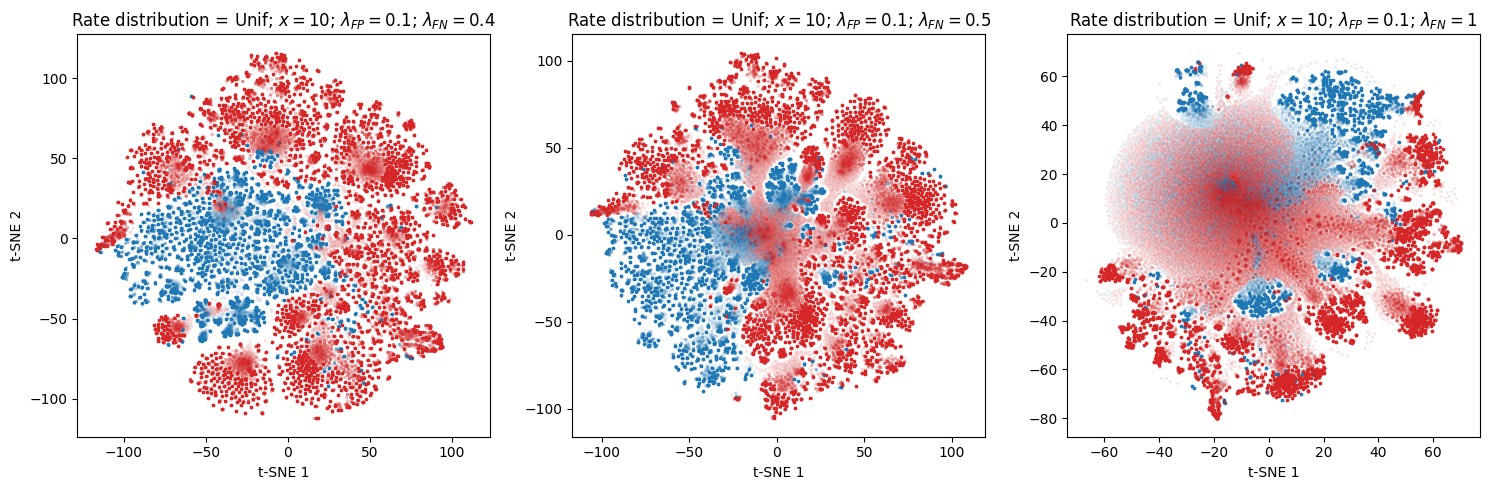

In [236]:
N = len(X) 

plt.figure(figsize=(15,5))
plt.subplot(1,3,1)
plot_tsne_pnenot_noise_vs_clean(X_emb_04)
plt.title(rf"Rate distribution = Unif; "rf"$x = 10$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 0.4$")

plt.subplot(1,3,2)   
plot_tsne_pnenot_noise_vs_clean(X_emb_05)
plt.title(rf"Rate distribution = Unif; "rf"$x = 10$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 0.5$")

plt.subplot(1,3,3)
plot_tsne_pnenot_noise_vs_clean(X_emb_1)
plt.title(rf"Rate distribution = Unif; "rf"$x = 10$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 1$")

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_level_tsne_phen_clones.svg", format="svg", bbox_inches='tight') #<-------save as pdf
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_level_tsne_phen_clones.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf

plt.tight_layout()

plt.show()

In [238]:
unique_taxa = sorted(set(taxa_group_names))

# pick a colormap with many distinct colors
cmap = plt.get_cmap("tab20", len(unique_taxa))

taxa_to_color = {
    taxon: cmap(i) for i, taxon in enumerate(unique_taxa)
}

colors_taxa = np.array([taxa_to_color[t] for t in taxa_group_names_augmented])

In [252]:
def plot_tsne_taxa_clones(X_emb):
    plt.scatter(
        X_emb[mask_head, 0],
        X_emb[mask_head, 1],
        c=colors_taxa[mask_head],
        alpha=1,
        s=1.5,
        edgecolors="black",
        linewidths=0.3
    )
    
    mask_tail = np.arange(len(y_np)) >= N
    
    # aerobe
    plt.scatter(
        X_emb[mask_tail, 0],
        X_emb[mask_tail, 1],
        color=colors_taxa[mask_tail],
        alpha=0.04,
        s=3,
        label="aerobe (augmented)"
    )
    
    plt.title(f"t-SNE | noise type = {noise_type}; x = {x_noisy_samples}; fp_rate_mean = {fp_rate_mean}, fn_rate_mean = {fn_rate_mean}")
    
    plt.xlabel("t-SNE 1", fontsize=10)
    
    plt.tick_params(axis='both', labelsize=10)

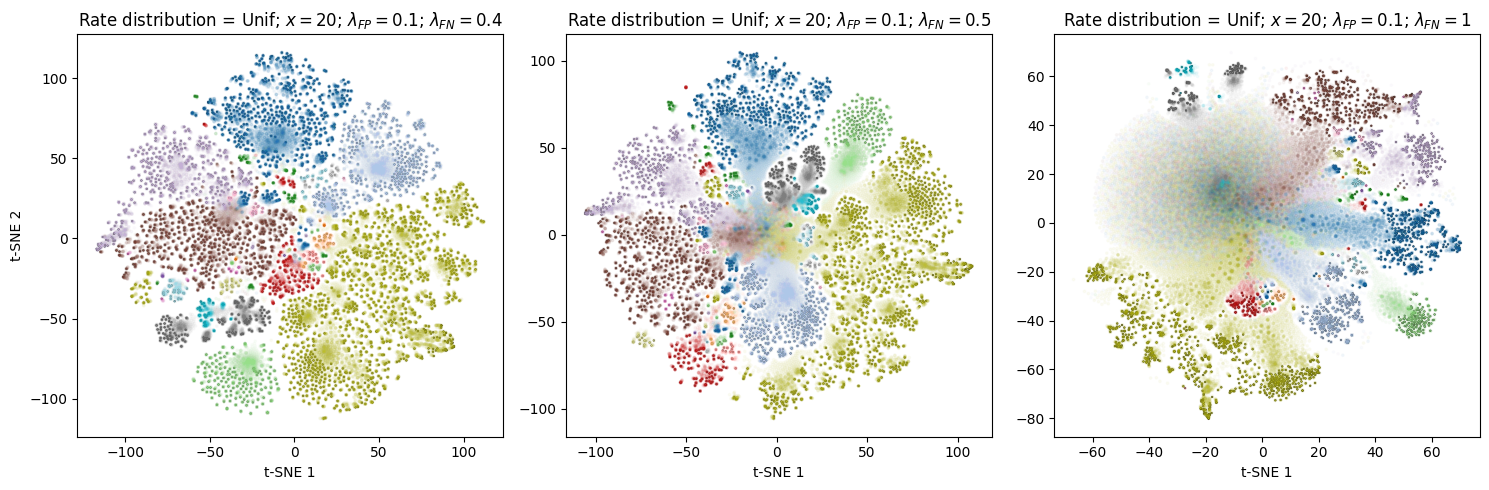

In [253]:
plt.figure(figsize=(15,5))

mask_head = np.arange(len(y_np)) < N

plt.subplot(1,3,1)
plot_tsne_taxa_clones(X_emb_04)
plt.ylabel("t-SNE 2", fontsize=10)
plt.title(rf"Rate distribution = Unif; "rf"$x = 20$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 0.4$")

plt.subplot(1,3,2)   
plot_tsne_taxa_clones(X_emb_05)
plt.title(rf"Rate distribution = Unif; "rf"$x = 20$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 0.5$")

plt.subplot(1,3,3)
plot_tsne_taxa_clones(X_emb_1)
plt.title(rf"Rate distribution = Unif; "rf"$x = 20$; "rf"$\lambda_{{FP}} = 0.1$; "rf"$\lambda_{{FN}} = 1$")

plt.tight_layout()

plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_level_tsne_taxon_clones.svg", format="svg", bbox_inches='tight') #<-------save as pdf
plt.savefig(f"{OUTPUT_DIRECTORY}/plots/noise_level_tsne_taxon_clones.pdf", format="pdf", bbox_inches='tight') #<-------save as pdf

plt.show()

### 5.  Ancestral phenotype prediction

#### 5.1  ML predictions

In [5]:
# Read the annotated count table and get the list of COGs from there
aerob_cogs = pd.read_csv("../data_aerob/all_gene_annotations.tsv", sep="\t")
X_column_names = aerob_cogs.columns[aerob_cogs.columns.str.startswith("COG")].tolist()

In [6]:
# Read the GTDB tables for the genome taxonomy

import polars as pl

BAC_TSV = '../data_preparation/gtdb_files/bac120_metadata_r202.tsv'
ARC_TSV = '../data_preparation/gtdb_files/ar122_metadata_r202.tsv'

tax_level = "phylum"
tax_levels = {"domain": 0, "phylum": 1, "class": 2, "order": 3, "family": 4}

gtdb_df = pl.concat([pl.read_csv(BAC_TSV, separator="\t"),
    pl.read_csv(ARC_TSV, separator="\t")])
gtdb_df = gtdb_df[['accession', "gtdb_taxonomy"]]
for key in tax_levels.keys():
    tax_level = tax_levels[key]
    gtdb_df = gtdb_df.with_columns(pl.col("gtdb_taxonomy").str.split(';').list.get(tax_levels[key]).alias(key))
gtdb_df = gtdb_df.drop("gtdb_taxonomy")
gtdb_df = gtdb_df.to_pandas()

In [7]:
# Get the species tree leaf node names
leaves_acc_names = pd.read_csv("../ancestral_data/GenomesInfo.csv", sep=",")
columns_to_keep = ['accession', 'ShortCode']
leaves_acc_names = leaves_acc_names[columns_to_keep]
leaves_acc_names

,accession,ShortCode
0,GB_GCA_003599535.1,AABM5X1
1,GB_GCA_005223185.1,AABM5X2
2,GB_GCA_002127415.1,AABM5X3
3,GB_GCA_003598085.1,Abys1
4,GB_GCA_003223555.1,Acid1
...,...,...
1002,GB_GCA_001775395.1,Zixi1
1003,GB_GCA_002791595.1,Zixi2
1004,GB_GCA_003105265.1,Zixi3
1005,GB_GCA_002838945.1,Zixi4


In [8]:
leave_nodes_with_taxonomy = pd.merge(leaves_acc_names, gtdb_df, on="accession", how="inner")
leave_nodes_with_taxonomy

,accession,ShortCode,domain,phylum,class,order,family
0,GB_GCA_003599535.1,AABM5X1,d__Bacteria,p__AABM5-125-24,c__B3-LCP,o__B3-LCP,f__B3-LCP
1,GB_GCA_005223185.1,AABM5X2,d__Bacteria,p__AABM5-125-24,c__B3-LCP,o__B3-LCP,f__B3-LCP
2,GB_GCA_002127415.1,AABM5X3,d__Bacteria,p__AABM5-125-24,c__AABM5-125-24,o__AABM5-125-24,f__AABM5-125-24
3,GB_GCA_003598085.1,Abys1,d__Bacteria,p__Abyssubacteria,c__SURF-5,o__SURF-5,f__SURF-5
4,GB_GCA_003223555.1,Acid1,d__Bacteria,p__Acidobacteriota,c__Vicinamibacteria,o__Fen-336,f__Fen-336
...,...,...,...,...,...,...,...
992,GB_GCA_001775395.1,Zixi1,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__UBA10806,f__UBA10806
993,GB_GCA_002791595.1,Zixi2,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__UM-FILTER-46-8,f__UM-FILTER-46-8
994,GB_GCA_003105265.1,Zixi3,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__GN15,f__FEB-12
995,GB_GCA_002838945.1,Zixi4,d__Bacteria,p__Zixibacteria,c__MSB-5A5,o__GN15,f__PGXB01


In [9]:
# Read the tree file and pivot it into a COG count table
df = pd.read_csv('../ancestral_data/TableAncestralRoot1_aggregated_byCOG.tsv', sep='\t', dtype={'column_name': str})
df = df.T

df.columns = df.loc['COG']
df = df.drop(index='COG')
df.columns.name = None

pivot_df = df.apply(pd.to_numeric)
pivot_df.index = pivot_df.index.str.replace(r'\(\d+\)$', '', regex=True)

pivot_df

,COG0001,COG0002,COG0003,COG0004,COG0005,COG0006,COG0007,COG0008,COG0010,COG0012,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.00,0.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X2,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X3,0.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Abys1,1.00,1.00,1.00,1.00,1.00,0.00,0.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Acid1,1.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,0.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,0.55,0.58,0.76,0.37,1.00,0.01,0.12,1.00,1.00,0.23,...,0.01,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2009,0.26,0.38,0.09,0.31,0.91,0.00,0.24,0.68,0.08,1.00,...,0.02,0.0,0.00,0.0,0.02,0.0,0.0,0.0,0.09,0.0
2010,0.24,0.51,0.91,0.13,0.70,0.00,0.06,1.00,0.68,0.15,...,0.01,0.0,0.03,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2011,0.08,0.07,0.14,0.08,0.29,0.00,0.05,0.88,0.23,0.13,...,0.00,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.00,0.0


In [10]:
# # Optionally: threshold the COG count values to convert them to 0/1s
# threshold = 0.01
# pivot_df = pivot_df.applymap(lambda x: 0 if x <= threshold else max(x, 1))
# pivot_df

In [11]:
# Find COGs that are in the intersection between the COG set from the species tree and the COGs from the annotated data
cogs_from_mastertable = list(pivot_df.columns)
cogs_intersect = list(set(cogs_from_mastertable) & set(X_column_names))
cogs_intersect = sorted(cogs_intersect, key=lambda x: int(x[3:]))

# Apply the intersection COGs to the species tree count table
tree_nodes_data = pivot_df[cogs_intersect]
tree_nodes_data

,COG0001,COG0002,COG0003,COG0004,COG0005,COG0007,COG0008,COG0010,COG0012,COG0013,...,COG5611,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663
AABM5X1,1.00,0.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X2,1.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
AABM5X3,0.00,0.00,1.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Abys1,1.00,1.00,1.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
Acid1,1.00,1.00,1.00,1.00,1.00,0.00,1.00,0.00,1.00,1.00,...,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.0,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,0.55,0.58,0.76,0.37,1.00,0.12,1.00,1.00,0.23,1.00,...,0.01,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2009,0.26,0.38,0.09,0.31,0.91,0.24,0.68,0.08,1.00,0.48,...,0.02,0.0,0.00,0.0,0.02,0.0,0.0,0.0,0.09,0.0
2010,0.24,0.51,0.91,0.13,0.70,0.06,1.00,0.68,0.15,0.94,...,0.01,0.0,0.03,0.0,0.00,0.0,0.0,0.0,0.01,0.0
2011,0.08,0.07,0.14,0.08,0.29,0.05,0.88,0.23,0.13,0.67,...,0.00,0.0,0.01,0.0,0.00,0.0,0.0,0.0,0.00,0.0


In [12]:
# # Optionally: visualise the the species tree count table

# from sklearn.manifold import TSNE

# tsne = TSNE(
#     n_components=2,
#     perplexity=30,
#     random_state=42,
#     init="pca"
# )

# embedding = tsne.fit_transform(tree_nodes_data.values)

# tsne_df = pd.DataFrame(
#     embedding,
#     columns=["TSNE1", "TSNE2"],
#     index=tree_nodes_data.index
# )
# tsne_df["node_name"] = tree_nodes_data.index.astype(str)

In [13]:
# numeric_values = []
# is_numeric = []

# for genome in tree_nodes_data.index.astype(str):
#     try:
#         numeric_values.append(int(genome))
#         is_numeric.append(True)
#     except ValueError:
#         numeric_values.append(np.nan)
#         is_numeric.append(False)

# tsne_df["numeric_id"] = numeric_values
# tsne_df["is_numeric"] = is_numeric

# fig, ax = plt.subplots(figsize=(8, 6))

# numeric_mask = tsne_df["is_numeric"]

# scatter = ax.scatter(
#     tsne_df.loc[numeric_mask, "TSNE1"],
#     tsne_df.loc[numeric_mask, "TSNE2"],
#     c=tsne_df.loc[numeric_mask, "numeric_id"],
#     cmap="viridis",
#     s=10,
#     alpha=0.8
# )

# ax.scatter(
#     tsne_df.loc[~numeric_mask, "TSNE1"],
#     tsne_df.loc[~numeric_mask, "TSNE2"],
#     color="black",
#     #edgecolor="black",
#     s=2,
#     label="Extant genomes"
# )

# cbar = plt.colorbar(scatter, ax=ax)
# cbar.set_label("Genome ID")

# ax.set_xlabel("t-SNE 1")
# ax.set_ylabel("t-SNE 2")
# ax.set_title("t-SNE of COG count matrix")
# ax.legend()

# plt.tight_layout()
# plt.show()

In [14]:
# Prepare model train data
aerob_annot = pd.read_csv("../data_aerob/bacdive_scrape_20230315.json.parsed.anaerobe_vs_aerobe.with_cyanos.csv", sep="\t")
merged_tab  = pd.merge(aerob_cogs, aerob_annot, on="accession", how="inner") 
merged_tab

,accession,COG0001,COG0002,COG0003,COG0004,COG0005,COG0007,COG0008,COG0010,COG0012,...,COG5615,COG5621,COG5625,COG5632,COG5640,COG5643,COG5650,COG5652,COG5663,oxytolerance
0,GB_GCA_000010565.1,1,1,0,1,2,1,1,1,1,...,0,0,0,2,0,0,0,0,1,anaerobe
1,GB_GCA_000018565.1,1,1,1,3,3,0,1,1,1,...,0,0,0,1,1,0,0,0,0,aerobe
2,GB_GCA_000145985.1,1,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,anaerobe
3,GB_GCA_000210715.1,0,0,0,0,0,1,1,0,1,...,0,0,0,0,0,0,0,0,0,anaerobe
4,GB_GCA_000214705.1,1,1,0,1,2,1,1,2,1,...,0,0,0,0,0,0,0,1,0,anaerobe
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3179,RS_GCF_902813185.1,1,1,0,2,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,aerobe
3180,RS_GCF_902825325.1,2,1,0,1,0,0,0,1,1,...,0,0,0,0,0,0,0,0,0,aerobe
3181,RS_GCF_902859645.1,1,2,0,1,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,aerobe
3182,RS_GCF_902859695.1,1,2,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,aerobe


In [15]:
# Prepare phenotype annotation vector
y_label_train = torch.tensor(merged_tab["oxytolerance"].map({"aerobe": 1, "anaerobe": 0}).to_numpy(), dtype=torch.long)
numeric_df = merged_tab.iloc[:, 1:-1]
numeric_values = torch.tensor(numeric_df.values, dtype=torch.float32)
numeric_values = (numeric_values> 0).int()  
numeric_values.shape

X_column_names = merged_tab.columns.tolist()[1:-1]
name_to_idx = {name: i for i, name in enumerate(X_column_names)}

# Keep only those in cogs_intersect AND present in X_column_names
keep_indices = [name_to_idx[cog] for cog in cogs_intersect if cog in name_to_idx]

# Filter tensor and column names
X_val_train_filtered = numeric_values[:, keep_indices]
X_column_names_filtered = [X_column_names[i] for i in keep_indices]
X_val_train_filtered.shape

torch.Size([3184, 2672])

In [16]:
# Initialize XGBoost for training

device = DEVICE
use_gpu = torch.cuda.is_available()
tree_method = "gpu_hist" if use_gpu else "hist"
predictor = "gpu_predictor" if use_gpu else "auto"

def make_xgb():
    return XGBClassifier(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=1.0,
        reg_lambda=2.0,
        min_child_weight=5,
        tree_method=tree_method,
        n_jobs=-1
    )

In [17]:
from utils.utils_ancestral_predict import augment_data_with_noise

# Augment X train with the noise 
x = 100
fp_rate_mean = 0.1
fn_rate_mean = 0.5
noise_type = "unif"

X_augmented, y_augmented = augment_data_with_noise(X_val_train_filtered, y_label_train, x, fp_rate_mean, fn_rate_mean, noise_type=noise_type)#, filename=None)
X_augmented.shape

torch.Size([321584, 2672])

In [18]:
from xgboost import XGBClassifier
from sklearn.pipeline import make_pipeline

# Train a model on noise augmented data
pipe = make_pipeline(make_xgb())
pipe.fit(X_augmented.cpu(), y_augmented.cpu());

In [21]:
import joblib

filename = f"apply_to_tree_trained_models_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x}.pkl"
joblib.dump(pipe, f"{OUTPUT_DIRECTORY}/{TRAINED_MOD_DIR}/{filename}")

['../data_aerob/outputs/phylum/trained_models_train_val_test/apply_to_tree_trained_models_fp_0.1_fn_0.5_noise_type_unif_x_100.pkl']

In [22]:
# Convert tree genomes to a tensor
numeric_df = tree_nodes_data.select_dtypes(include=["number"])
ancestral_nodes_tensor = torch.tensor(numeric_df.to_numpy())

# Apply the trained model to the tree genomes
y_pred_ancestr_nodes = pipe.predict(ancestral_nodes_tensor.cpu())

# Predict the probabilities of each class and find the maximum probability
y_proba_ancestr_nodes = pipe.predict_proba(ancestral_nodes_tensor.cpu())
max_proba = [max(x) for x in y_proba_ancestr_nodes]

In [23]:
# Genrate a table with all genome names from the species tree and the model predictions

# Count for the correctly predicted extant genomes (the ones whose true annotations we know)
correct = 0
total = 0

# Arrays for storing the values for each tree node 
phylum = []              # name of the node phyla
oxytolerance = []        # predicted phenotype label
annot_vs_pred_label = [] # a label indicating wheather the genome's label was predicted by the model or already annotaed  

tree_node_names_list = tree_nodes_data.index.tolist()
merged_df = pd.merge(aerob_annot, leaves_acc_names, on="accession", how="left")

# Iterate over all nodes in the species tree 
for idx, node in enumerate(tree_node_names_list):
    if node in list(merged_df['ShortCode']):
        
        oxytol = merged_df.loc[merged_df["ShortCode"] == node, "oxytolerance"]
        oxytolerance.append(oxytol.iloc[0])
        annot_vs_pred_label.append("annot")

        # Count the number or correctly predicted extant genomes
        if (oxytol.iloc[0] == "aerobe" and y_pred_ancestr_nodes[idx] == 1) or (oxytol.iloc[0] == "anaerobe" and y_pred_ancestr_nodes[idx] == 0):
            correct += 1
        total +=1    
        
    else:
        annot_vs_pred_label.append("predict")
        oxytolerance.append("aerobe" if y_pred_ancestr_nodes[idx] == 1 else "anaerobe")  

    if node in list(leave_nodes_with_taxonomy['ShortCode']):
        phyl = leave_nodes_with_taxonomy.loc[leave_nodes_with_taxonomy["ShortCode"] == node, "phylum"]
        phylum.append(phyl.iloc[0])
    else:
        phylum.append(None)

# Generate the final table
df_pred = pd.DataFrame({
    'NodeName': tree_node_names_list,
    'oxytolerance': oxytolerance,
    'annot_or_predict':annot_vs_pred_label,
    'max_proba': max_proba,
    'phylum': phylum,
    "proba_and_uncert": y_proba_ancestr_nodes[:, 1]
})

print(f"Correct predict = {correct} of {total}; which is {correct/total}")
df_pred


Correct predict = 242 of 242; which is 1.0


,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert
0,AABM5X1,anaerobe,predict,0.997900,p__AABM5-125-24,0.002100
1,AABM5X2,anaerobe,predict,0.998693,p__AABM5-125-24,0.001307
2,AABM5X3,anaerobe,predict,0.999577,p__AABM5-125-24,0.000423
3,Abys1,anaerobe,predict,0.999971,p__Abyssubacteria,0.000029
4,Acid1,aerobe,predict,0.995918,p__Acidobacteriota,0.995918
...,...,...,...,...,...,...
2008,2008,anaerobe,predict,0.991995,None,0.008005
2009,2009,anaerobe,predict,0.879364,None,0.120635
2010,2010,anaerobe,predict,0.966424,None,0.033576
2011,2011,anaerobe,predict,0.880159,None,0.119841


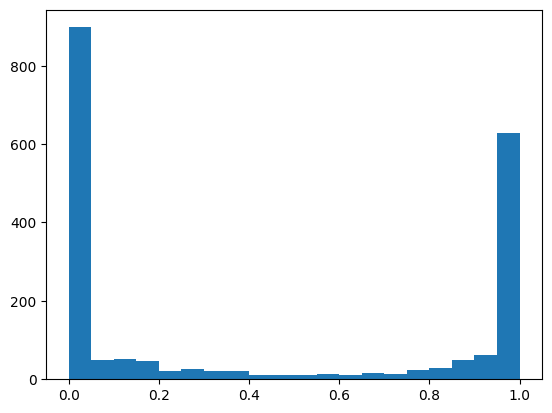

In [24]:
plt.hist(df_pred["proba_and_uncert"], bins=20);

In [25]:
# Print the prediction results for the root node
print(df_pred.loc[df_pred["NodeName"] == '2012', "oxytolerance"].iloc[0])
print(df_pred.loc[df_pred["NodeName"] == '2012', "max_proba"].iloc[0])

anaerobe
0.7293842


#### 5.1.  MK predictions

In [26]:
# Read a phenotype annotation file
all_gene_annot = "../data_aerob/bacdive_scrape_20230315.json.parsed.anaerobe_vs_aerobe.with_cyanos.csv"

df_annot = pd.read_csv(all_gene_annot, sep="\t")
all_gen_access = df_annot["accession"]
df_annot

,accession,oxytolerance
0,RS_GCF_001040945.1,aerobe
1,RS_GCF_007995015.1,aerobe
2,RS_GCF_900100655.1,aerobe
3,RS_GCF_000243235.1,aerobe
4,RS_GCF_003387535.1,aerobe
...,...,...
3179,RS_GCF_001870225.1,aerobe
3180,RS_GCF_001870905.1,aerobe
3181,RS_GCF_001890765.1,aerobe
3182,RS_GCF_001939115.1,aerobe


In [27]:
# Read the gtdb metadata and merge them with the phenotype annotation file
gtdb_arc_name = "../data_preparation/gtdb_files/ar122_metadata_r202.tsv"
gtdb_arc = pd.read_csv(gtdb_arc_name, sep="\t")
gtdb_arc = gtdb_arc[["accession", "gtdb_taxonomy"]]

gtdb_bac_name = "../data_preparation/gtdb_files/bac120_metadata_r202.tsv"
gtdb_bac = pd.read_csv(gtdb_bac_name, sep="\t")
gtdb_bac = gtdb_bac[["accession", "gtdb_taxonomy"]]

df_combined = pd.concat([gtdb_arc, gtdb_bac])

df_annot_wuth_taxa = pd.merge(df_annot, df_combined, on="accession", how="inner")

# The taxonomy levels for which the phenotype agreement index is calculated
levels = ["domain","phylum","class","order","family","genus","species"]

df_annot_wuth_taxa[levels] = (
    df_annot_wuth_taxa["gtdb_taxonomy"]
    .str.split(";", expand=True)
    .reindex(columns=range(7))  # ensures 7 columns even if missing
)

# remove prefixes like d__, p__, etc.
for col in levels:
    df_annot_wuth_taxa[col] = df_annot_wuth_taxa[col].str.replace(r"^[a-z]__", "", regex=True)

# drop original column
df_annot_wuth_taxa = df_annot_wuth_taxa.drop(columns=["gtdb_taxonomy"])

df_annot_wuth_taxa

/scratch/ipykernel_2205039/3882575764.py:7: DtypeWarning: Columns (61,65,74,82,83) have mixed types. Specify dtype option on import or set low_memory=False.
  gtdb_bac = pd.read_csv(gtdb_bac_name, sep="\t")


,accession,oxytolerance,domain,phylum,class,order,family,genus,species
0,RS_GCF_001040945.1,aerobe,Bacteria,Proteobacteria,Gammaproteobacteria,Burkholderiales,Burkholderiaceae,Herbaspirillum,Herbaspirillum seropedicae
1,RS_GCF_007995015.1,aerobe,Bacteria,Bacteroidota,Bacteroidia,Flavobacteriales,Luteibaculaceae,Luteibaculum,Luteibaculum oceani
2,RS_GCF_900100655.1,aerobe,Bacteria,Proteobacteria,Alphaproteobacteria,Kiloniellales,Rhodovibrionaceae,Limimonas,Limimonas halophila
3,RS_GCF_000243235.1,aerobe,Bacteria,Bacteroidota,Bacteroidia,Flavobacteriales,Flavobacteriaceae,Gillisia,Gillisia limnaea
4,RS_GCF_003387535.1,aerobe,Bacteria,Proteobacteria,Gammaproteobacteria,Pseudomonadales,Moraxellaceae,Paraperlucidibaca,Paraperlucidibaca baekdonensis
...,...,...,...,...,...,...,...,...,...
3179,RS_GCF_001870225.1,aerobe,Bacteria,Cyanobacteria,Cyanobacteriia,Gloeomargaritales,Gloeomargaritaceae,Gloeomargarita,Gloeomargarita lithophora
3180,RS_GCF_001870905.1,aerobe,Bacteria,Cyanobacteria,Cyanobacteriia,Cyanobacteriales,Geitlerinemaceae_A,PCC-9228,PCC-9228 sp001870905
3181,RS_GCF_001890765.1,aerobe,Bacteria,Cyanobacteria,Cyanobacteriia,Cyanobacteriales,Spirulinaceae,Spirulina,Spirulina major
3182,RS_GCF_001939115.1,aerobe,Bacteria,Cyanobacteria,Cyanobacteriia,Neosynechococcales_A,Neosynechococcaceae_A,GCF-001939115,GCF-001939115 sp001939115


In [28]:
from utils.utils_ancestral_predict import read_acc, acc_key

data_directory = "data_aerob"

TIME_UNIT_FACTOR = 1.0   # 1000 if branch lengths are in Ga
TREE_FILE = "../ancestral_data/C65.tree"
GENOMES_INFO = "../ancestral_data/GenomesInfo.csv"
BAC_TSV = "../data_preparation/gtdb_files/bac120_metadata_r202.tsv"
ARC_TSV = "../data_preparation/gtdb_files/ar122_metadata_r202.tsv"

gtdb = pd.concat([
    pd.read_csv(BAC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
    pd.read_csv(ARC_TSV, sep="\t", usecols=["accession", "gtdb_taxonomy"]),
])
tax_by_acc = dict(zip(gtdb["accession"].map(acc_key), gtdb["gtdb_taxonomy"].str.split(";")))

# All accessions in the dataset (every genome appears in train, val or test of any split)
_base = f"../{data_directory}/input_data/class"
ALL_ACC = sorted(set(
    read_acc(f"{_base}/train_annot_class_tax_level_split_0")   
    + read_acc(f"{_base}/test_annot_class_tax_level_split_0")
))
phylum_of = {a: tax_by_acc[acc_key(a)][1] for a in ALL_ACC if acc_key(a) in tax_by_acc}

In [29]:
from ete3 import Tree

# Load GTDB trees
tree_path_bact  = "../phylo_trees/bac120_r220.tree"  
tree_bact       = Tree(tree_path_bact, format=1, quoted_node_names=True)
nodes_bact      = {leaf.name: leaf for leaf in tree_bact.iter_leaves()}
leaf_names_bact = set(tree_bact.get_leaf_names())

tree_path_arch  = "../phylo_trees/ar53_r220.tree" 
tree_arch       = Tree(tree_path_arch, format=1, quoted_node_names=True)
nodes_arch      = {leaf.name: leaf for leaf in tree_arch.iter_leaves()}
leaf_names_arch = set(tree_arch.get_leaf_names())

#  Find the percentage of the annotated genomes that are not present in the tree genomes
count_not_present = 0
for genome in all_gen_access:
    if genome not in leaf_names_bact and genome not in leaf_names_arch:
        count_not_present += 1
count_not_present/len(set(all_gen_access))  

0.09648845302119582

In [30]:
from pathlib import Path
import pandas as pd
from pastml.acr import pastml_pipeline


def run_pastml_split(
    tree,
    train_accessions,
    train_labels,
    test_accessions,
    split_id,
    tax_level,
    output_dir="pastml_output",
):
    train_accessions = list(map(str, train_accessions))
    test_accessions = list(map(str, test_accessions))

    train_label_map = {
        acc: str(int(label))
        for acc, label in zip(train_accessions, train_labels)
    }

    # Map prefix-free accessions to the original tree-tip names.
    available_tips = set(tree.get_leaf_names())
    normalized_tips = {
        tip.removeprefix("RS_").removeprefix("GB_"): tip
        for tip in available_tips
    }

    # Convert split accessions to names used in the tree.
    train_tip_map = {
        acc: normalized_tips[acc]
        for acc in train_accessions
        if acc in normalized_tips
    }
    test_tip_map = {
        acc: normalized_tips[acc]
        for acc in test_accessions
        if acc in normalized_tips
    }

    tips_to_keep = set(train_tip_map.values()) | set(test_tip_map.values())

    print(
        f"{tax_level}, split {split_id}: "
        f"{len(train_tip_map)}/{len(train_accessions)} training and "
        f"{len(test_tip_map)}/{len(test_accessions)} test genomes matched."
    )

    if not train_tip_map or not test_tip_map:
        raise ValueError("No matched training or test tips for this tree.")

    # Prune a copy of the tree.
    tree_split = tree.copy()
    tree_split.prune(list(tips_to_keep), preserve_branch_length=True)
    
    # Remove internal labels that PastML cannot parse.
    # Preserve leaf names and branch lengths.
    for node in tree_split.traverse():
        if not node.is_leaf():
            node.name = ""
            node.support = 1.0
    
    split_dir = Path(output_dir) / tax_level / f"split_{split_id}"
    split_dir.mkdir(parents=True, exist_ok=True)

    tree_file = split_dir / "tree.nwk"
    tree_split.write(
        outfile=str(tree_file),
        format=1,
        quoted_node_names=True,
    )

    # Use original tree-tip names in the PastML data file.
    # Only training genomes receive known states.
    tip_labels = {
        train_tip_map[acc]: label
        for acc, label in train_label_map.items()
        if acc in train_tip_map
    }

    df_states = pd.DataFrame({
        "accession": sorted(tips_to_keep)
    })
    df_states["phenotype"] = df_states["accession"].map(tip_labels)
    df_states.to_csv(split_dir / "training_states.csv", index=False)

    pastml_pipeline(
        tree=str(tree_file),
        data=str(split_dir / "training_states.csv"),
        data_sep=",",
        id_index=0,
        columns=["phenotype"],
        prediction_method="MPPA",
        model="F81",
        work_dir=str(split_dir / "pastml"),
        verbose=True,
    )

    return {
        "split_dir": str(split_dir),
        "tree_file": str(tree_file),
        "data_file": str(split_dir / "training_states.csv"),
        "tips_to_keep": tips_to_keep,
        "train_tip_map": train_tip_map,
        "test_tip_map": test_tip_map,
    }

In [31]:
# Map each domain to its corresponding GTDB tree
trees_by_domain = {
    "Bacteria": tree_bact,
    "Archaea": tree_arch,
}

domain_by_accession = (
    df_annot_wuth_taxa
    .drop_duplicates("accession")
    .set_index("accession")["domain"]
    .to_dict()
)

domain_by_accession = {
    str(acc).removeprefix("RS_").removeprefix("GB_"): domain
    for acc, domain in zip(
        df_annot_wuth_taxa["accession"],
        df_annot_wuth_taxa["domain"]
    )
}

In [32]:
import logging

logging.disable(logging.DEBUG)

In [33]:
LABEL_MAP = {"anaerobe": 0, "aerobe": 1} 

In [34]:
from pathlib import Path
from tqdm import tqdm
import numpy as np

from utils.utils_ancestral_predict import read_splits

NUM_SPLITS_TO_READ = 30
TAX_LEVELS = ["random", "family", "order", "class", "phylum"]

pastml_runs = []

for tax_level in tqdm(TAX_LEVELS, desc="Tax levels"):

    splits = read_splits(
        tax_level,
        data_directory,
        NUM_SPLITS_TO_READ,
        LABEL_MAP,
        ALL_ACC,
        phylum_of,
    )

    for split_id, split in tqdm(
        splits.items(), desc=f"Processing {tax_level}"
    ):

        acc_train = list(map(str, split["acc_train"]))
        y_train = np.asarray(split["y_train"]).astype(int)

        acc_test = list(map(str, split["acc_test"]))
        y_test = np.asarray(split["y_test"]).astype(int)

        for domain, tree in trees_by_domain.items():

            tax_level_domain = f"{tax_level}_{domain.lower()}"

            # Skip if PastML output already exists.
            output_file = (
                Path("pastml_output")
                / tax_level_domain
                / f"split_{split_id}"
                / "pastml"
                / "combined_ancestral_states.tab"
            )

            if output_file.exists():
                print(
                    f"Skipping {tax_level_domain}, split {split_id}: "
                    "output exists"
                )
                continue

            # Select genomes belonging to this domain.
            train_idx = [
                i for i, acc in enumerate(acc_train)
                if domain_by_accession.get(acc) == domain
            ]

            test_idx = [
                i for i, acc in enumerate(acc_test)
                if domain_by_accession.get(acc) == domain
            ]

            if not train_idx or not test_idx:
                continue

            train_acc_domain = [acc_train[i] for i in train_idx]
            train_y_domain = y_train[train_idx]

            test_acc_domain = [acc_test[i] for i in test_idx]
            test_y_domain = y_test[test_idx]

            try:
                result = run_pastml_split(
                    tree=tree,
                    train_accessions=train_acc_domain,
                    train_labels=train_y_domain,
                    test_accessions=test_acc_domain,
                    split_id=split_id,
                    tax_level=tax_level_domain,
                    output_dir="pastml_output",
                )
            except ValueError as e:
                if "tip annotations" in str(e) and "unknown" in str(e):
                    print(
                        f"Skipping {tax_level_domain}, split {split_id}: "
                        f"insufficient annotated tree tips ({e})"
                    )
                    continue
                raise

            if result is None:
                continue

            pastml_runs.append({
                "tax_level": tax_level,
                "split_id": split_id,
                "domain": domain,
                "result": result,
                "test_accessions": test_acc_domain,
                "y_test": test_y_domain,
            })

Tax levels:  20%|██████████████████▌                                                                          | 1/5 [00:28<01:55, 28.98s/it]

Skipping random_bacteria, split 0: output exists
Skipping random_archaea, split 0: output exists
Skipping random_bacteria, split 1: output exists
Skipping random_archaea, split 1: output exists
Skipping random_bacteria, split 2: output exists
Skipping random_archaea, split 2: output exists
Skipping random_bacteria, split 3: output exists
Skipping random_archaea, split 3: output exists
Skipping random_bacteria, split 4: output exists
Skipping random_archaea, split 4: output exists
Skipping random_bacteria, split 5: output exists
Skipping random_archaea, split 5: output exists
Skipping random_bacteria, split 6: output exists
Skipping random_archaea, split 6: output exists
Skipping random_bacteria, split 7: output exists
Skipping random_archaea, split 7: output exists
Skipping random_bacteria, split 8: output exists
Skipping random_archaea, split 8: output exists
Skipping random_bacteria, split 9: output exists
Skipping random_archaea, split 9: output exists
Skipping random_bacteria, spli


Tax levels:  40%|█████████████████████████████████████▏                                                       | 2/5 [00:53<01:18, 26.18s/it]

Skipping family_bacteria, split 0: output exists
Skipping family_archaea, split 0: output exists
Skipping family_bacteria, split 1: output exists
Skipping family_archaea, split 1: output exists
Skipping family_bacteria, split 2: output exists
Skipping family_archaea, split 2: output exists
Skipping family_bacteria, split 3: output exists
Skipping family_archaea, split 3: output exists
Skipping family_bacteria, split 4: output exists
Skipping family_archaea, split 4: output exists
Skipping family_bacteria, split 5: output exists
Skipping family_archaea, split 5: output exists
Skipping family_bacteria, split 6: output exists
Skipping family_archaea, split 6: output exists
Skipping family_bacteria, split 7: output exists
Skipping family_archaea, split 7: output exists
Skipping family_bacteria, split 8: output exists
Skipping family_archaea, split 8: output exists
Skipping family_bacteria, split 9: output exists
Skipping family_archaea, split 9: output exists
Skipping family_bacteria, spli


Tax levels:  60%|███████████████████████████████████████████████████████▊                                     | 3/5 [01:21<00:54, 27.16s/it]

...

Skipping class_bacteria, split 0: output exists
Skipping class_archaea, split 0: output exists
Skipping class_bacteria, split 1: output exists
Skipping class_archaea, split 1: output exists
Skipping class_bacteria, split 2: output exists
Skipping class_archaea, split 2: output exists
Skipping class_bacteria, split 3: output exists
Skipping class_archaea, split 3: output exists
Skipping class_bacteria, split 4: output exists
Skipping class_archaea, split 4: output exists
Skipping class_bacteria, split 5: output exists
Skipping class_archaea, split 5: output exists
Skipping class_bacteria, split 6: output exists
Skipping class_bacteria, split 7: output exists
Skipping class_archaea, split 7: output exists
Skipping class_bacteria, split 8: output exists
Skipping class_archaea, split 8: output exists
Skipping class_bacteria, split 9: output exists
Skipping class_archaea, split 9: output exists
Skipping class_bacteria, split 10: output exists
Skipping class_archaea, split 10: output exists



Processing phylum:   0%|                                                                                             | 0/30 [00:00<?, ?it/s]

Skipping phylum_bacteria, split 0: output exists
Skipping phylum_bacteria, split 1: output exists
Skipping phylum_bacteria, split 2: output exists
Skipping phylum_bacteria, split 3: output exists
Skipping phylum_bacteria, split 4: output exists
Skipping phylum_bacteria, split 5: output exists
Skipping phylum_bacteria, split 6: output exists
Skipping phylum_bacteria, split 7: output exists
Skipping phylum_archaea, split 7: output exists
Skipping phylum_bacteria, split 8: output exists
Skipping phylum_archaea, split 8: output exists
Skipping phylum_bacteria, split 9: output exists
Skipping phylum_archaea, split 9: output exists
Skipping phylum_bacteria, split 10: output exists
Skipping phylum_bacteria, split 11: output exists
Skipping phylum_archaea, split 11: output exists
Skipping phylum_bacteria, split 12: output exists
Skipping phylum_bacteria, split 13: output exists
Skipping phylum_bacteria, split 14: output exists
phylum_archaea, split 14: 2/2 training and 94/101 test genomes matc


Tax levels: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [01:51<00:00, 22.24s/it]

Skipping phylum_archaea, split 14: insufficient annotated tree tips (97.9% of tip annotations for character "phenotype" are unknown, not enough data to infer ancestral states. Check your annotation file and if its ids correspond to the tree tip/node names.)
Skipping phylum_bacteria, split 15: output exists
Skipping phylum_bacteria, split 16: output exists
Skipping phylum_bacteria, split 17: output exists
Skipping phylum_archaea, split 17: output exists
Skipping phylum_bacteria, split 18: output exists
Skipping phylum_bacteria, split 19: output exists
Skipping phylum_archaea, split 19: output exists
Skipping phylum_bacteria, split 20: output exists
Skipping phylum_bacteria, split 21: output exists
Skipping phylum_archaea, split 21: output exists
Skipping phylum_bacteria, split 22: output exists
Skipping phylum_bacteria, split 23: output exists
Skipping phylum_archaea, split 23: output exists
Skipping phylum_bacteria, split 24: output exists
Skipping phylum_archaea, split 24: output exis

In [36]:
# print("Probability file:", probs_file)
# print("Available columns:", probs.columns.tolist())

# # Check the training labels for this split and domain
# split = splits[split_id]
# acc_train = list(map(str, split["acc_train"]))
# y_train = np.asarray(split["y_train"]).astype(int)

# train_idx = [
#     i for i, acc in enumerate(acc_train)
#     if domain_by_accession.get(acc) == domain
# ]

# print("Training label counts:")
# print(pd.Series(y_train[train_idx]).value_counts().sort_index())

In [35]:
from collections import defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import matthews_corrcoef

NUM_SPLITS_TO_READ = 30
TAX_LEVELS = ["random", "family", "order", "class", "phylum"]
OUTPUT_DIR = Path("pastml_output")
N_BINS = 10   # must match the binning used for the XGBoost ECE


def ece_maxprob(confidence, correct, n_bins=N_BINS):
    """Expected Calibration Error with max-probability confidence and
    equal-width bins on [0, 1]."""
    confidence = np.asarray(confidence, dtype=float)
    correct = np.asarray(correct, dtype=float)
    bin_idx = np.minimum((confidence * n_bins).astype(int), n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        in_bin = bin_idx == b
        if in_bin.any():
            ece += abs(correct[in_bin].mean() - confidence[in_bin].mean()) * in_bin.mean()
    return ece


pooled = defaultdict(lambda: {"y_true": [], "y_pred": [], "p1": [], "n_test": 0})
mcc_details = []   # per-domain rows, for diagnostics only

for tax_level in TAX_LEVELS:
    splits = read_splits(tax_level, data_directory, NUM_SPLITS_TO_READ,
                         LABEL_MAP, ALL_ACC, phylum_of)

    for split_id, split in splits.items():
        acc_test = list(map(str, split["acc_test"]))
        y_test = np.asarray(split["y_test"]).astype(int)

        for domain in trees_by_domain:
            # True labels of this domain's test genomes
            test_label = {a: y for a, y in zip(acc_test, y_test)
                          if domain_by_accession.get(a) == domain}
            if not test_label:
                continue
            pooled[(tax_level, split_id)]["n_test"] += len(test_label)

            probs_file = (OUTPUT_DIR / f"{tax_level}_{domain.lower()}"
                          / f"split_{split_id}" / "pastml"
                          / "marginal_probabilities.character_phenotype.model_F81.tab")
            if not probs_file.exists():
                continue

            probs = pd.read_csv(probs_file, sep="\t")
            probs["node"] = probs["node"].astype(str)
            # Same name normalisation as in run_pastml_split
            probs["accession"] = (probs["node"]
                                  .str.removeprefix("RS_")
                                  .str.removeprefix("GB_"))
            matched = probs[probs["accession"].isin(test_label)]
            if matched.empty:
                continue

            # Probability of state 1 for each masked tip.
            # If PastML saw only one state, that state has probability 1.
            state_cols = [c for c in ["0", "1"] if c in probs.columns]
            if len(state_cols) == 2:
                p = matched[["0", "1"]].astype(float).to_numpy()
                p = p / p.sum(axis=1, keepdims=True)   # guard against rounding
                p1 = p[:, 1]
            else:
                p1 = np.full(len(matched), 1.0 if state_cols[0] == "1" else 0.0)

            y_pred = (p1 > 0.5).astype(int)   # exact 0.5 ties -> 0, as argmax did
            y_true = matched["accession"].map(test_label).astype(int).to_numpy()

            pooled[(tax_level, split_id)]["y_true"].extend(y_true)
            pooled[(tax_level, split_id)]["y_pred"].extend(y_pred)
            pooled[(tax_level, split_id)]["p1"].extend(p1)

            mcc_details.append({
                "tax_level": tax_level, "split_id": split_id, "domain": domain,
                "n_test": len(test_label), "n_matched": len(matched),
                "single_state_run": len(state_cols) == 1,
            })

# One value per split, over both domains together
mcc_by_split_pooled = defaultdict(dict)
ece_by_split_pooled = defaultdict(dict)
brier_by_split_pooled = defaultdict(dict)
split_rows = []

for (tax_level, split_id), d in pooled.items():
    if not d["y_true"]:
        continue
    y_true = np.asarray(d["y_true"], dtype=int)
    y_pred = np.asarray(d["y_pred"], dtype=int)
    p1 = np.asarray(d["p1"], dtype=float)

    confidence = np.maximum(p1, 1.0 - p1)          # probability of predicted class
    correct = (y_true == y_pred).astype(int)

    mcc = matthews_corrcoef(y_true, y_pred)
    ece = ece_maxprob(confidence, correct)
    brier = np.mean((p1 - y_true) ** 2)

    mcc_by_split_pooled[tax_level][split_id] = mcc
    ece_by_split_pooled[tax_level][split_id] = ece
    brier_by_split_pooled[tax_level][split_id] = brier

    split_rows.append({
        "tax_level": tax_level, "split_id": split_id,
        "n_scored": len(y_true), "n_test": d["n_test"],
        "mcc": mcc, "accuracy": correct.mean(),
        "mean_confidence": confidence.mean(), "ece": ece, "brier": brier,
    })

mcc_by_split_pooled = dict(mcc_by_split_pooled)
ece_by_split_pooled = dict(ece_by_split_pooled)
brier_by_split_pooled = dict(brier_by_split_pooled)

mcc_details_df = pd.DataFrame(mcc_details)
pastml_split_df = pd.DataFrame(split_rows)

# Summary per taxonomic level
print(pastml_split_df
      .groupby("tax_level", sort=False)[["mcc", "accuracy", "mean_confidence", "ece", "brier"]]
      .agg(["mean", "std"])
      .round(3))

             mcc        accuracy        mean_confidence           ece         \
            mean    std     mean    std            mean    std   mean    std   
tax_level                                                                      
random     0.910  0.015    0.960  0.007           0.961  0.003  0.014  0.005   
family     0.844  0.060    0.926  0.032           0.891  0.017  0.060  0.025   
order      0.641  0.206    0.847  0.089           0.846  0.036  0.104  0.058   
class      0.223  0.384    0.612  0.272           0.751  0.079  0.290  0.164   
phylum     0.012  0.046    0.466  0.268           0.704  0.119  0.338  0.210   

           brier         
            mean    std  
tax_level                
random     0.033  0.005  
family     0.066  0.019  
order      0.114  0.041  
class      0.238  0.144  
phylum     0.334  0.148  


In [36]:
pooled_df = pd.DataFrame([
    {"tax_level": lvl, "split_id": sid, "mcc_pooled": mcc,
     "n_scored": len(pooled[(lvl, sid)]["y_true"]),
     "n_test": pooled[(lvl, sid)]["n_test"]}
    for lvl, d in mcc_by_split_pooled.items()
    for sid, mcc in d.items()
])
print(pooled_df.groupby("tax_level", sort=False)["mcc_pooled"].agg(["mean", "std", "count"]))

               mean       std  count
tax_level                           
random     0.910307  0.014786     30
family     0.843782  0.059826     30
order      0.641296  0.206012     30
class      0.222942  0.384352     30
phylum     0.011793  0.046379     30


In [37]:
# from collections import defaultdict
# import numpy as np

# mcc_by_split_avg = defaultdict(dict)

# # Group MCC values by taxonomy level and split
# grouped = defaultdict(list)

# for row in mcc_details:
#     grouped[(row["tax_level"], row["split_id"])].append(row["mcc"])

# # Average across Bacteria and Archaea for each split
# for (tax_level, split_id), mcc_values in grouped.items():
#     mcc_by_split_avg[tax_level][split_id] = np.mean(mcc_values)

# # Convert to a regular dictionary
# mcc_by_split_avg = dict(mcc_by_split_avg)

# # # Inspect results
# # for tax_level, split_values in mcc_by_split_avg.items():
# #     print(f"\n{tax_level}:")
# #     for split_id, mcc in sorted(split_values.items()):
# #         print(f"  Split {split_id}: MCC = {mcc:.3f}")

# mcc_by_split_avg

In [38]:
TAX_LEVELS = ["random", "family", "order", "class", "phylum"]

In [48]:
from tqdm import tqdm
from utils.utils_ancestral_predict import  nearest_train_times

per_split_time = {}   # level -> {split_id: median distance in Ma}
per_split_n = {}
#for lvl in LEVELS:
for tax_level in tqdm(TAX_LEVELS, desc="Tax levels"):     #tax_levels
    splits = read_splits(tax_level, DATA_DIRECTORY, NUM_SPLITS_TO_READ, LABEL_MAP, ALL_ACC, phylum_of)
    per_split_time[tax_level] = {}
    per_split_n[tax_level] = {}
    for split_id, d in splits.items():
        times, missing = nearest_train_times(d["acc_train"], d["acc_test"], RANK_IDX, RANKS, tax_by_acc, taxon_to_tips, acc_key, tree, leaf_by_name, age, parent, coarsest_rank="genus")
        per_split_time[tax_level][split_id] = np.min(times) #or median
        per_split_n[tax_level][split_id] = (len(times), missing, len(d["acc_test"]))
    vals = list(per_split_time[tax_level].values())
    print(f"{tax_level:>7}: metric over {len(vals)} splits = {np.median(vals):6.0f} Ma "
          f"(range {np.min(vals):.0f} to {np.max(vals):.0f})")

#pd.DataFrame(per_split_time).to_csv("divergence_time_per_split.csv")

Tax levels:  20%|██████████████████▌                                                                          | 1/5 [01:28<05:55, 88.80s/it]

 random: metric over 30 splits =      0 Ma (range 0 to 0)


Tax levels:  40%|█████████████████████████████████████▏                                                       | 2/5 [02:52<04:16, 85.61s/it]

 family: metric over 30 splits =    962 Ma (range 724 to 1438)


Tax levels:  60%|███████████████████████████████████████████████████████▊                                     | 3/5 [04:21<02:54, 87.41s/it]

  order: metric over 30 splits =   1168 Ma (range 724 to 2061)


Tax levels:  80%|██████████████████████████████████████████████████████████████████████████▍                  | 4/5 [05:52<01:28, 88.58s/it]

  class: metric over 30 splits =   3286 Ma (range 2890 to 4619)


Tax levels: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 5/5 [06:59<00:00, 83.87s/it]

 phylum: metric over 30 splits =   5118 Ma (range 4619 to 5753)


In [49]:
TAX_LEVELS = ["random", "family", "order", "class", "phylum"]
NUM_SPLITS_TO_READ = 30

data_directory = "data_aerob"

label_map = {"anaerobe": 0, "aerobe": 1} 

In [50]:
import pandas as pd

model_metric_per_split = {}

for tax_level in TAX_LEVELS:
    OUTPUT_DIRECTORY = f"../{data_directory}/outputs/{tax_level}"

    df = pd.read_csv(f"{OUTPUT_DIRECTORY}/model_metrics_per_split.csv") 

    metrics_dict = defaultdict(list, {
        col: df[col].dropna().tolist()
        for col in df.columns
    })

    model_metric_per_split[tax_level] = metrics_dict

model_metric_per_split.keys()

dict_keys(['random', 'family', 'order', 'class', 'phylum'])

In [51]:
model_metric_per_split['random'].keys()

dict_keys(['mcc', 'balanced_accuracy', 'accuracy', 'precision', 'recall', 'f1', 'ece'])

In [52]:
import pandas as pd

def read_mcc_values_per_split(csv_name):
    phylog_pred_metr_per_split = {}
    
    for tax_level in TAX_LEVELS:
        OUTPUT_DIRECTORY = f"../{data_directory}/outputs/{tax_level}"
        print(OUTPUT_DIRECTORY)
    
        df = pd.read_csv(f"{OUTPUT_DIRECTORY}/{csv_name}") 
    
        metrics_dict = defaultdict(list, {
            col: df[col].dropna().tolist()
            for col in df.columns
        })
    
        phylog_pred_metr_per_split[tax_level] = metrics_dict
    
    phylog_mcc_values = {
        tax_level: [
            values[-1]
            for key, values in metrics.items()
            if key != "Unnamed: 0" and values
        ]
        for tax_level, metrics in phylog_pred_metr_per_split.items()
    }
    return phylog_mcc_values

#mcc_values



In [53]:
phylog_mcc_values = read_mcc_values_per_split("phylog_pred_metr_metrics_per_split.csv")


../data_aerob/outputs/random
../data_aerob/outputs/family
../data_aerob/outputs/order
../data_aerob/outputs/class
../data_aerob/outputs/phylum


In [54]:
# from tqdm.auto import tqdm
# from utils.utils import one_split_phylogeny_prediction

# phylog_ece_values = {}
# phylog_pred_rows = []   # saved predictions, so this never needs rerunning

# for TAX_LEVEL in tqdm(["random", "family", "order", "class", "phylum"], desc="Tax levels"):
#     all_splits_dict = read_splits(TAX_LEVEL, DATA_DIRECTORY, NUM_SPLITS_TO_READ,
#                                   LABEL_MAP, ALL_ACC, phylum_of)
#     ece_per_split = {}

#     for split_id, split in tqdm(all_splits_dict.items(), desc=f"{TAX_LEVEL} splits", leave=False):
#         acc_train = list(map(str, split["acc_train"]))
#         y_train   = np.asarray(split["y_train"]).astype(int)
#         acc_test  = list(map(str, split["acc_test"]))
#         y_test    = np.asarray(split["y_test"]).astype(int)

#         train_labels_dict = dict(zip(acc_train, y_train.tolist()))
#         test_labels_dict  = dict(zip(acc_test,  y_test.tolist()))

#         if TAX_LEVEL == "random":
#             # Nearest single genome: p1 is its label (0 or 1)
#             true_l, pred_l, p1, acc_scored = [], [], [], []
#             for g in acc_test:#, desc=f"split {split_id} test genomes", leave=False):
#                 nodes = nodes_bact if g in nodes_bact else (nodes_arch if g in nodes_arch else None)
#                 if nodes is None:
#                     continue
#                 best_d, best_lab = float("inf"), None
#                 for t in acc_train:
#                     if t in nodes:
#                         d = nodes[g].get_distance(nodes[t])
#                         if d < best_d:
#                             best_d, best_lab = d, train_labels_dict[t]
#                 if best_lab is None:
#                     continue
#                 true_l.append(test_labels_dict[g])
#                 pred_l.append(best_lab)
#                 p1.append(float(best_lab))
#                 acc_scored.append(g)
#         else:
#             true_l, pred_l, p1 = one_split_phylogeny_prediction(
#                 set(acc_train), acc_test, train_labels_dict, test_labels_dict,
#                 nodes_bact, nodes_arch,
#             )
#             acc_scored = None   # the function does not return accessions

#         p1 = np.asarray(p1, dtype=float)
#         conf = np.maximum(p1, 1 - p1)
#         correct = (np.asarray(true_l) == np.asarray(pred_l)).astype(int)
#         ece_per_split[split_id] = ece_maxprob(conf, correct)

#         for i, (yt, yp, pp) in enumerate(zip(true_l, pred_l, p1)):
#             phylog_pred_rows.append({
#                 "tax_level": TAX_LEVEL, "split_id": split_id,
#                 "accession": acc_scored[i] if acc_scored else None,
#                 "y_true": int(yt), "y_pred": int(yp), "p1": float(pp),
#             })

#     phylog_ece_values[TAX_LEVEL] = ece_per_split

# # Save once, reuse later
# phylog_pred_df = pd.DataFrame(phylog_pred_rows)
# phylog_pred_df.to_csv("phylogeny_predictions_with_fractions.csv", index=False)

In [55]:
def rolling_curve(x, y, window=1000, step=25, min_n=5, trim_right=True):
    """Rolling mean and SD of y over x using a centred window.
    Returns NaN where the window holds fewer than min_n points,
    so the line breaks instead of following a handful of points."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    half = window / 2
    hi = x.max() - half if trim_right else x.max()
    grid = np.arange(x.min(), hi + step, step)

    mean = np.full(len(grid), np.nan)
    sd = np.full(len(grid), np.nan)
    for i, g in enumerate(grid):
        in_win = np.abs(x - g) <= half
        if in_win.sum() >= min_n:
            mean[i] = y[in_win].mean()
            sd[i] = y[in_win].std()
    return grid, mean, sd

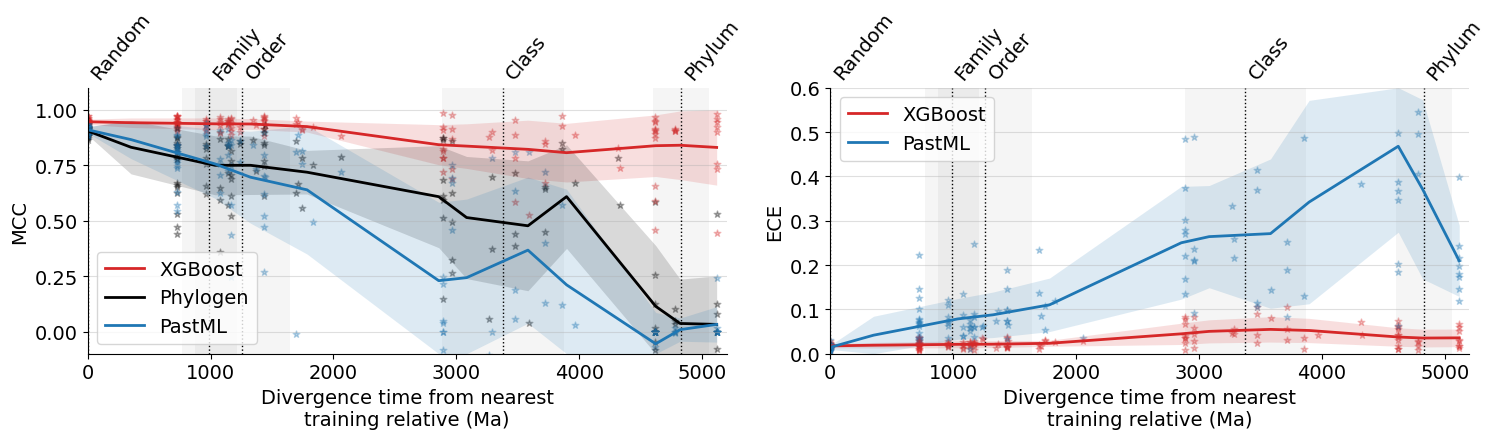

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from utils.utils_ancestral_predict import rolling_mean_std_curve

tax_levels = ["random", "family", "order", "class", "phylum"]

colors = {
    "XGBoost": "tab:red",
    "Phylogen": "black",
    "PastML": "tab:blue",
}

FONTSIZE = 14
max_time = 5200


def get_score(values, split_id):
    """Return the score for a split from a list/array or dictionary."""
    if isinstance(values, dict):
        return values.get(split_id, np.nan)
    if 0 <= split_id < len(values):
        return values[split_id]
    return np.nan


def plot_metric(ax, sources, ylabel, ylim):
    """Plot per-split scatter points and pooled rolling mean ± SD.

    sources: {method: {tax_level: list (indexed by split_id) or dict}}
    """
    all_points = {method: ([], []) for method in sources}
    tick_pos, tick_lab = [], []

    for tax_level in tax_levels:
        times_by_split = per_split_time.get(tax_level, {})
        points = {method: ([], []) for method in sources}

        for split_id, time in times_by_split.items():
            if not np.isfinite(time) or time > max_time:
                continue

            scores = {
                method: get_score(src.get(tax_level, {}), split_id)
                for method, src in sources.items()
            }

            # Use the same splits for all methods in this panel.
            if not all(np.isfinite(float(v)) for v in scores.values()):
                continue

            for method, score in scores.items():
                points[method][0].append(float(time))
                points[method][1].append(float(score))

        # Pool points across taxonomy levels for rolling curves.
        for method in sources:
            all_points[method][0].extend(points[method][0])
            all_points[method][1].extend(points[method][1])

        # Individual split points (excluded from the legend).
        for method in sources:
            x, y = points[method]
            ax.scatter(
                x,
                y,
                color=colors[method],
                s=25,
                marker="*",
                alpha=0.3,
                label="_nolegend_",
            )

        # Mean divergence time ± SD for this taxonomy level.
        level_times = np.asarray(list(times_by_split.values()), dtype=float)
        level_times = level_times[
            np.isfinite(level_times) & (level_times <= max_time)
        ]

        if len(level_times):
            mu, sd = level_times.mean(), level_times.std()
            ax.axvspan(
                mu - sd, mu + sd,
                color="grey",
                alpha=0.08,
                linewidth=0,
            )
            ax.axvline(
                mu,
                color="black",
                linestyle=":",
                linewidth=1,
                label="_nolegend_",
            )
            tick_pos.append(mu)
            tick_lab.append(tax_level.capitalize())

    # Rolling mean ± SD for each method.
    # Labels are assigned to the lines so the legend shows line samples.
    for method, (x_values, y_values) in all_points.items():
        x = np.asarray(x_values, dtype=float)
        y = np.asarray(y_values, dtype=float)

        mask = np.isfinite(x) & np.isfinite(y)
        x, y = x[mask], y[mask]

        if len(x) < 2:
            continue

        order = np.argsort(x)
        x, y = x[order], y[order]

        x_mean, y_mean, y_std = rolling_mean_std_curve(
            x, y, window=1000
        )

        # Clip uncertainty bands to the plotted y-range.
        ax.fill_between(
            x_mean,
            np.clip(y_mean - y_std, *ylim),
            np.clip(y_mean + y_std, *ylim),
            color=colors[method],
            alpha=0.15,
            linewidth=0,
            label="_nolegend_",
        )

        # Label the rolling-mean line, not the scatter points.
        ax.plot(
            x_mean,
            y_mean,
            color=colors[method],
            linewidth=2,
            label=method,
        )

    # Taxonomy-level labels on the top axis.
    sec = ax.secondary_xaxis("top")
    sec.set_xticks(tick_pos)
    sec.set_xticklabels(
        tick_lab,
        rotation=50,
        ha="left",
        fontsize=FONTSIZE,
    )
    sec.tick_params(axis="x", length=0)
    sec.spines["top"].set_visible(False)

    ax.set_xlabel(
        "Divergence time from nearest\ntraining relative (Ma)",
        fontsize=FONTSIZE,
    )
    ax.set_ylabel(ylabel, fontsize=FONTSIZE)
    ax.tick_params(axis="both", labelsize=FONTSIZE)
    ax.set_xlim(0, max_time)
    ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.4)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


# ---------------------------------------------------------------------------
# Per-split scores
# ---------------------------------------------------------------------------

# Left panel: MCC for all three methods.
# PastML: pooled MCC, one value per split over Bacteria + Archaea.
mcc_sources = {
    "XGBoost": {
        lvl: model_metric_per_split[lvl]["mcc"]
        for lvl in tax_levels
    },
    "Phylogen": {
        lvl: phylog_mcc_values[lvl]
        for lvl in tax_levels
    },
    "PastML": mcc_by_split_pooled,
}

# Right panel: ECE for XGBoost and PastML.
# The nearest-clade predictor does not output probabilities.
ece_sources = {
    "XGBoost": {
        lvl: model_metric_per_split[lvl]["ece"]
        for lvl in tax_levels
    },
    "PastML": ece_by_split_pooled,
}


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------

fig, (ax_mcc, ax_ece) = plt.subplots(
    1, 2, figsize=(15, 4.5)
)

plot_metric(
    ax_mcc,
    mcc_sources,
    "MCC",
    ylim=(-0.1, 1.1),
)

plot_metric(
    ax_ece,
    ece_sources,
    "ECE",
    ylim=(0.0, 0.6),
)

# Legends now use solid line samples rather than scatter markers.
ax_mcc.legend(fontsize=FONTSIZE, loc="lower left")
ax_ece.legend(fontsize=FONTSIZE, loc="upper left")

# Optional panel labels.
# ax_mcc.text(-0.08, 1.12, "a)", transform=ax_mcc.transAxes,
#             fontsize=FONTSIZE + 2)
# ax_ece.text(-0.08, 1.12, "b)", transform=ax_ece.transAxes,
#             fontsize=FONTSIZE + 2)

plt.tight_layout()

# Save as vector graphics.
fig.savefig(
    f"{OUTPUT_DIRECTORY}/plots/divergence_time_metrics.svg",
    format="svg",
    bbox_inches="tight",
)
fig.savefig(
    f"{OUTPUT_DIRECTORY}/plots/divergence_time_metrics.pdf",
    format="pdf",
    bbox_inches="tight",
)

plt.show()

In [80]:
[
    (
        np.mean(list(ece_sources['PastML'][tax].values())),
        np.std(list(ece_sources['PastML'][tax].values()))
    )
    for tax in ece_sources['PastML'].keys()
]

[(np.float64(0.014407354420714258), np.float64(0.004776458541303125)),
 (np.float64(0.06025502498071466), np.float64(0.02414159823126146)),
 (np.float64(0.10419228030951073), np.float64(0.056875916404814306)),
 (np.float64(0.29030860381949436), np.float64(0.16129977012138896)),
 (np.float64(0.33788637452691805), np.float64(0.2061479562174638))]

In [78]:
[
    (
        np.mean(list(ece_sources['PastML'][tax])),
        np.std(list(ece_sources['PastML'][tax]))
    )
    for tax in ece_sources['PastML'].keys()
]


[(np.float64(14.5), np.float64(8.65544144839919)),
 (np.float64(14.5), np.float64(8.65544144839919)),
 (np.float64(14.5), np.float64(8.65544144839919)),
 (np.float64(14.5), np.float64(8.65544144839919)),
 (np.float64(14.5), np.float64(8.65544144839919))]

In [ ]:
f"{OUTPUT_DIRECTORY}/plots/divergence_time_metrics.pdf"

In [65]:
rows = []

for tax_level in TAX_LEVELS:
    splits = read_splits(tax_level, data_directory, NUM_SPLITS_TO_READ,
                         LABEL_MAP, ALL_ACC, phylum_of)

    for split_id, split in splits.items():
        acc_test = list(map(str, split["acc_test"]))
        y_test = np.asarray(split["y_test"]).astype(int)

        for domain in trees_by_domain:
            test_label = {a: y for a, y in zip(acc_test, y_test)
                          if domain_by_accession.get(a) == domain}
            if not test_label:
                continue

            probs_file = (OUTPUT_DIR / f"{tax_level}_{domain.lower()}"
                          / f"split_{split_id}" / "pastml"
                          / "marginal_probabilities.character_phenotype.model_F81.tab")
            if not probs_file.exists():
                continue

            probs = pd.read_csv(probs_file, sep="\t")
            probs["node"] = probs["node"].astype(str)
            probs["accession"] = (probs["node"]
                                  .str.removeprefix("RS_")
                                  .str.removeprefix("GB_"))
            matched = probs[probs["accession"].isin(test_label)]
            if matched.empty:
                continue

            state_cols = [c for c in ["0", "1"] if c in probs.columns]
            if len(state_cols) == 2:
                p = matched[["0", "1"]].astype(float).to_numpy()
                y_pred = p.argmax(axis=1)
                max_post = p.max(axis=1)
            else:  # PastML saw only one state in this domain
                y_pred = np.full(len(matched), int(state_cols[0]))
                max_post = np.ones(len(matched))

            y_true = matched["accession"].map(test_label).astype(int).to_numpy()

            for yt, yp, mp in zip(y_true, y_pred, max_post):
                rows.append({
                    "tax_level": tax_level, "split_id": split_id, "domain": domain,
                    "y_true": yt, "y_pred": yp, "max_post": mp,
                })

diag = pd.DataFrame(rows)
print(diag.groupby("tax_level", sort=False).agg(
    n=("y_true", "size"),
    true_frac_1=("y_true", "mean"),
    pred_frac_1=("y_pred", "mean"),
    mean_max_post=("max_post", "mean"),
))

               n  true_frac_1  pred_frac_1  mean_max_post
tax_level                                                
random     17218     0.661517     0.680276       0.961202
family     17669     0.628955     0.679382       0.891277
order      18515     0.666649     0.717310       0.846705
class      21950     0.599134     0.321276       0.747192
phylum     19716     0.696794     0.422195       0.722649


In [66]:
diag["correct"] = (diag["y_true"] == diag["y_pred"]).astype(int)
print(diag.groupby("tax_level", sort=False)[["correct", "max_post"]].mean())

            correct  max_post
tax_level                    
random     0.959984  0.961202
family     0.926481  0.891277
order      0.848879  0.846705
class      0.599954  0.747192
phylum     0.464496  0.722649


In [106]:
from Bio import Phylo

# Read the already existing tree file that we annotate with the model predictions below 
tree = Phylo.read("../ancestral_data/C65.tree", "newick")

In [107]:
n_leaves = tree.count_terminals()
n_internal = len(tree.get_nonterminals())
n_total = len(list(tree.find_clades()))

print(f"Leaf nodes: {n_leaves}")
print(f"Internal nodes: {n_internal}")
print(f"Total nodes: {n_total}")

Leaf nodes: 1007
Internal nodes: 1006
Total nodes: 2013


In [82]:
for node in tree.get_nonterminals()[:5]:
    print("name:", node.name, "| confidence:", node.confidence)

name: None | confidence: 2012
name: None | confidence: 2009
name: None | confidence: 2007
name: None | confidence: 2005
name: None | confidence: 2003


In [83]:
phenotype_col = "oxytolerance"

# Map phenotype names to states
phenotype_map = {
    "anaerobe": 0,
    "aerobe": 1
}

# Create accession -> phenotype dictionary
phenotype_dict = (
    merged_tab
    .set_index("accession")[phenotype_col]
    .map(phenotype_map)
    .dropna()
    .to_dict()
)

len(phenotype_dict.keys())


3161

In [84]:
# accession -> tree leaf name
accession_to_leaf = (
    leaves_acc_names
    .set_index("accession")["ShortCode"]
    .to_dict()
)

leaf_phenotype_dict = {
    accession_to_leaf[accession]: phenotype
    for accession, phenotype in phenotype_dict.items()
    if accession in accession_to_leaf
}

# df_pred

len(leaf_phenotype_dict)

242

In [85]:
import pandas as pd

# leaf_phenotype_dict: {leaf_name: 0 or 1}
tip_df = pd.DataFrame({
    "id": list(leaf_phenotype_dict.keys()),
    "phenotype": list(leaf_phenotype_dict.values())
})

tip_df.to_csv("tip_states_oxygen.csv", index=False)

In [100]:
tip_df

,id,phenotype
0,Chlo27,1
1,Cyan21,1
2,Cyan26,1
3,Cyan8,1
4,Cyan36,1
...,...,...
237,Acti42,1
238,FirmB8,0
239,Aqui3,0
240,FirmA89,0


In [87]:
from pastml.acr import pastml_pipeline

pastml_pipeline(
    tree="../ancestral_data/C65.tree",
    data="tip_states_oxygen.csv",
    data_sep=",",
    id_index=0,
    columns=["phenotype"],
    prediction_method="MPPA",
    model="F81",
    work_dir="pastml_output",
    verbose=True
)

In [88]:
import os

for f in os.listdir("pastml_output"):
    print(f)

params.character_phenotype.method_MPPA.model_F81.tab
phylum_archaea
.ipynb_checkpoints
class_archaea
marginal_probabilities.character_phenotype.model_F81.tab
random_archaea
order_archaea
named.tree_C65.nwk
order_bacteria
random_bacteria
class_bacteria
family_archaea
phylum_bacteria
combined_ancestral_states.tab
named.tree_C65.nexus
family_bacteria


In [89]:
pastml_tree = Phylo.read("pastml_output/named.tree_C65.nwk", "newick")

for node in pastml_tree.get_nonterminals()[:5]:
    print("name:", node.name)

name: root
name: n0
name: n00
name: n1
name: n11


In [90]:
pastml_tree

Tree(rooted=False, weight=1.0)

In [91]:
def get_tipset(clade):
    return frozenset(leaf.name for leaf in clade.get_terminals())

pastml_tipset_by_name = {
    clade.name: get_tipset(clade)
    for clade in pastml_tree.find_clades()# get_nonterminals()
    if clade.name is not None
}

print(len(pastml_tipset_by_name), "PastML internal nodes with names")

2013 PastML internal nodes with names


In [92]:
nodename_by_tipset = {
    get_tipset(node): node.confidence
    for node in tree.get_nonterminals()
    if node.confidence is not None
}

print(len(nodename_by_tipset), "original tree internal nodes with a recovered NodeName")

1006 original tree internal nodes with a recovered NodeName


In [93]:
bio_tipsets = set(nodename_by_tipset.keys())
pastml_tipsets = set(pastml_tipset_by_name.values())

print("In original tree but not PastML:", len(bio_tipsets - pastml_tipsets))
print("In PastML but not original tree:", len(pastml_tipsets - bio_tipsets))

In original tree but not PastML: 0
In PastML but not original tree: 1007


In [94]:
probs = pd.read_csv(
    "pastml_output/marginal_probabilities.character_phenotype.model_F81.tab",
    sep="\t", index_col=0
)
probs = probs.astype(float)
print(probs.dtypes)
probs.head()

0    float64
1    float64
dtype: object


,0,1
node,,
root,0.999458,0.000542
n0,0.999178,0.000822
n285,0.999541,0.000459
n00,0.998285,0.001715
n279,0.993683,0.006317


In [95]:
pastml_results = []

for pastml_name, tipset in pastml_tipset_by_name.items():
    if tipset not in nodename_by_tipset:
        continue
    if pastml_name not in probs.index:
        continue

    matched_nodename = nodename_by_tipset[tipset]
    p0 = probs.loc[pastml_name, "0"]
    p1 = probs.loc[pastml_name, "1"]

    pastml_results.append({
        "NodeName": matched_nodename,
        "pastml_p0": p0,
        "pastml_p1": p1,
        "pastml_call": "aerobe" if p1 > p0 else "anaerobe",
        "pastml_confidence": max(p0, p1)
    })

pastml_df = pd.DataFrame(pastml_results)
print(len(pastml_df), "nodes matched")
pastml_df.head()

1006 nodes matched


,NodeName,pastml_p0,pastml_p1,pastml_call,pastml_confidence
0,2012,0.999458,0.000542,anaerobe,0.999458
1,2009,0.999178,0.000822,anaerobe,0.999178
2,2007,0.998285,0.001715,anaerobe,0.998285
3,2005,0.999504,0.000496,anaerobe,0.999504
4,2003,0.997264,0.002736,anaerobe,0.997264


In [96]:
pastml_df["NodeName"] = pastml_df["NodeName"].apply(lambda x: str(int(x)))
pastml_df

,NodeName,pastml_p0,pastml_p1,pastml_call,pastml_confidence
0,2012,0.999458,0.000542,anaerobe,0.999458
1,2009,0.999178,0.000822,anaerobe,0.999178
2,2007,0.998285,0.001715,anaerobe,0.998285
3,2005,0.999504,0.000496,anaerobe,0.999504
4,2003,0.997264,0.002736,anaerobe,0.997264
...,...,...,...,...,...
1001,1205,0.999871,0.000129,anaerobe,0.999871
1002,1670,0.999947,0.000053,anaerobe,0.999947
1003,1527,0.999025,0.000975,anaerobe,0.999025
1004,1197,0.989787,0.010213,anaerobe,0.989787


In [97]:
merged_df = df_pred.merge(pastml_df, on="NodeName", how="inner")
merged_df

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,pastml_p0,pastml_p1,pastml_call,pastml_confidence
0,1007,anaerobe,predict,0.999178,None,0.000822,0.839060,0.160940,anaerobe,0.839060
1,1008,anaerobe,predict,0.997605,None,0.002395,0.878898,0.121102,anaerobe,0.878898
2,1009,aerobe,predict,0.970755,None,0.970755,0.398063,0.601937,aerobe,0.601937
3,1010,anaerobe,predict,0.985595,None,0.014405,0.851077,0.148923,anaerobe,0.851077
4,1011,aerobe,predict,0.891262,None,0.891262,0.808768,0.191232,anaerobe,0.808768
...,...,...,...,...,...,...,...,...,...,...
1001,2008,anaerobe,predict,0.991995,None,0.008005,0.997829,0.002171,anaerobe,0.997829
1002,2009,anaerobe,predict,0.879364,None,0.120635,0.999178,0.000822,anaerobe,0.999178
1003,2010,anaerobe,predict,0.966424,None,0.033576,0.999458,0.000542,anaerobe,0.999458
1004,2011,anaerobe,predict,0.880159,None,0.119841,0.999541,0.000459,anaerobe,0.999541


In [102]:
from Bio import Phylo
import pandas as pd
from pastml.acr import pastml_pipeline

# 1. Run Wagner (Fitch) parsimony with the same tree and tip states as Mk
pastml_pipeline(
    tree="../ancestral_data/C65.tree",
    data="tip_states_oxygen.csv",
    data_sep=",",
    id_index=0,
    columns=["phenotype"],
    prediction_method="DOWNPASS",      # maximum parsimony; no model needed
    work_dir="pastml_output_wagner",   # separate folder, keeps Mk results
    verbose=True,
)

# 2. PastML's named tree for this run -> tip set of each named node
wagner_tree = Phylo.read("pastml_output_wagner/named.tree_C65.nwk", "newick")

wagner_tipset_by_name = {
    clade.name: get_tipset(clade)
    for clade in wagner_tree.find_clades()
    if clade.name is not None
}
print(len(wagner_tipset_by_name), "PastML (Wagner) nodes with names")

# 3. Reconstructed states: one row per node, or two rows if the node is tied
states = pd.read_csv(
    "pastml_output_wagner/combined_ancestral_states.tab",
    sep="\t", dtype=str,
)
states_by_node = states.groupby("node")["phenotype"].agg(lambda s: sorted(set(s)))
print((states_by_node.str.len() > 1).sum(), "tied nodes in PastML output (incl. tips)")

# 4. Match to the original NodeNames via tip sets
wagner_results = []
for wagner_name, tipset in wagner_tipset_by_name.items():
    if tipset not in nodename_by_tipset:      # tips and unmatched nodes are skipped
        continue
    if wagner_name not in states_by_node.index:
        continue

    node_states = states_by_node[wagner_name]
    tied = len(node_states) > 1
    if tied:
        call = "tie"
    else:
        call = "aerobe" if node_states[0] == "1" else "anaerobe"

    wagner_results.append({
        "NodeName": nodename_by_tipset[tipset],
        "wagner_call": call,
        "wagner_tied": tied,
    })

wagner_df = pd.DataFrame(wagner_results)
wagner_df["NodeName"] = wagner_df["NodeName"].apply(lambda x: str(int(x)))
print(len(wagner_df), "nodes matched;", wagner_df["wagner_tied"].sum(), "tied")

# 5. Add to the table that already holds XGBoost and Mk
merged_df = merged_df.merge(wagner_df, on="NodeName", how="inner")
print(len(merged_df), "nodes with XGBoost, Mk and Wagner")
merged_df[["NodeName", "oxytolerance", "pastml_call", "wagner_call", "wagner_tied"]].head()

2013 PastML (Wagner) nodes with names
308 tied nodes in PastML output (incl. tips)
1006 nodes matched; 158 tied
1006 nodes with XGBoost, Mk and Wagner


,NodeName,oxytolerance,pastml_call,wagner_call,wagner_tied
0,1007,anaerobe,anaerobe,anaerobe,False
1,1008,anaerobe,anaerobe,anaerobe,False
2,1009,aerobe,aerobe,aerobe,False
3,1010,anaerobe,anaerobe,anaerobe,False
4,1011,aerobe,anaerobe,anaerobe,False


In [103]:
merged_df

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,pastml_p0,pastml_p1,pastml_call,pastml_confidence,wagner_call,wagner_tied
0,1007,anaerobe,predict,0.999178,None,0.000822,0.839060,0.160940,anaerobe,0.839060,anaerobe,False
1,1008,anaerobe,predict,0.997605,None,0.002395,0.878898,0.121102,anaerobe,0.878898,anaerobe,False
2,1009,aerobe,predict,0.970755,None,0.970755,0.398063,0.601937,aerobe,0.601937,aerobe,False
3,1010,anaerobe,predict,0.985595,None,0.014405,0.851077,0.148923,anaerobe,0.851077,anaerobe,False
4,1011,aerobe,predict,0.891262,None,0.891262,0.808768,0.191232,anaerobe,0.808768,anaerobe,False
...,...,...,...,...,...,...,...,...,...,...,...,...
1001,2008,anaerobe,predict,0.991995,None,0.008005,0.997829,0.002171,anaerobe,0.997829,anaerobe,False
1002,2009,anaerobe,predict,0.879364,None,0.120635,0.999178,0.000822,anaerobe,0.999178,anaerobe,False
1003,2010,anaerobe,predict,0.966424,None,0.033576,0.999458,0.000542,anaerobe,0.999458,anaerobe,False
1004,2011,anaerobe,predict,0.880159,None,0.119841,0.999541,0.000459,anaerobe,0.999541,anaerobe,False


In [105]:
import numpy as np
import pandas as pd
from ete3 import Tree
from sklearn.metrics import cohen_kappa_score

# ------------------------------------------------------------------
# 1. Node properties: annotated descendants, informative nodes
# ------------------------------------------------------------------
tree = Tree("../ancestral_data/C65.tree", format=1)

tips = pd.read_csv("tip_states_oxygen.csv").dropna(subset=["phenotype"])
annot = dict(zip(tips["id"].astype(str), tips["phenotype"].astype(int)))
print(f"Annotated tips: {len(annot)}")

rows = []
for node in tree.traverse():
    if node.is_leaf():
        continue
    states = [annot[l.name] for l in node.get_leaves() if l.name in annot]
    rows.append({
        "NodeName": str(node.name),
        "n_annot_desc": len(states),
        "has_annot_desc": len(states) > 0,
        "informative": len(set(states)) == 2,   # annotated descendants of both phenotypes
    })
node_info = pd.DataFrame(rows)

df = merged_df.copy()
df["NodeName"] = df["NodeName"].astype(str)
df = df.drop(columns=[c for c in ["n_annot_desc", "has_annot_desc", "informative"]
                      if c in df.columns])
df = df.merge(node_info, on="NodeName", how="left")
print(f"Nodes with tree information: {df['has_annot_desc'].notna().sum()} / {len(df)}")
print(f"Wagner ties: {df['wagner_tied'].sum()}")

# ------------------------------------------------------------------
# 2. Methods, pairs and node sets
# ------------------------------------------------------------------
methods = {
    "XGBoost": "oxytolerance",
    "Mk": "pastml_call",
    "Wagner": "wagner_call",
}
if "dollo_call" in df.columns:          # added automatically once Dollo is available
    methods["Dollo"] = "dollo_call"

pairs = [("XGBoost", "Mk"), ("XGBoost", "Wagner"), ("Mk", "Wagner")]
if "Dollo" in methods:
    pairs += [("XGBoost", "Dollo"), ("Mk", "Dollo"), ("Wagner", "Dollo")]

node_sets = {
    "All": df,
    "With annotated descendants": df[df["has_annot_desc"]],
    "Without annotated descendants": df[~df["has_annot_desc"]],
    "Informative": df[df["informative"]],
}


def compare(sub, m1, m2):
    """Agreement statistics for two methods on a node subset.
    Nodes where Wagner is tied are excluded from any comparison involving Wagner."""
    c1, c2 = methods[m1], methods[m2]
    n_ties = 0
    if "Wagner" in (m1, m2):
        n_ties = int(sub["wagner_tied"].sum())
        sub = sub[~sub["wagner_tied"]]
    x, y = sub[c1], sub[c2]
    kappa = cohen_kappa_score(x, y) if (x.nunique() > 1 or y.nunique() > 1) else np.nan
    return {
        "n": len(sub),
        "excluded_ties": n_ties,
        "agreement": (x == y).mean(),
        "kappa": kappa,
        f"{m1} aerobe / {m2} anaerobe": int(((x == "aerobe") & (y == "anaerobe")).sum()),
        f"{m1} anaerobe / {m2} aerobe": int(((x == "anaerobe") & (y == "aerobe")).sum()),
    }


# ------------------------------------------------------------------
# 3. Pairwise agreement on every node set
# ------------------------------------------------------------------
records = []
for m1, m2 in pairs:
    for set_name, sub in node_sets.items():
        r = compare(sub, m1, m2)
        records.append({
            "pair": f"{m1} vs. {m2}", "nodes": set_name,
            "n": r["n"], "excluded_ties": r["excluded_ties"],
            "agreement": r["agreement"], "kappa": r["kappa"],
            "m1_aer_m2_ana": list(r.values())[4],
            "m1_ana_m2_aer": list(r.values())[5],
        })
agreement_df = pd.DataFrame(records)
print(agreement_df.round(3).to_string(index=False))

# ------------------------------------------------------------------
# 4. Fraction of aerobic calls per method and node set
# ------------------------------------------------------------------
frac = pd.DataFrame({
    set_name: {m: (sub[c] == "aerobe").mean() for m, c in methods.items()}
    for set_name, sub in node_sets.items()
}).T
print("\nFraction of nodes called aerobic:")
print(frac.round(3))

# ------------------------------------------------------------------
# 5. Root (LBCA)
# ------------------------------------------------------------------
root = str(tree.get_tree_root().name)
print("\nRoot:")
print(df.loc[df["NodeName"] == root,
             ["NodeName"] + list(methods.values()) + ["max_proba", "pastml_confidence"]])

# # ------------------------------------------------------------------
# # 6. LaTeX table: agreement (kappa) per pair and node set
# # ------------------------------------------------------------------
# agreement_df["cell"] = agreement_df.apply(
#     lambda r: f"{100 * r['agreement']:.1f}\\% ({r['kappa']:.2f})", axis=1)
# latex_tab = agreement_df.pivot(index="pair", columns="nodes", values="cell")
# latex_tab = latex_tab[list(node_sets.keys())]
# latex_tab = latex_tab.loc[[f"{a} vs. {b}" for a, b in pairs]]
# n_nodes = {k: len(v) for k, v in node_sets.items()}
# latex_tab.columns = [f"{k} (n={n_nodes[k]})" for k in latex_tab.columns]
# print("\n" + latex_tab.to_latex(escape=False))

Annotated tips: 242
Nodes with tree information: 1006 / 1006
Wagner ties: 158
              pair                         nodes    n  excluded_ties  agreement  kappa  m1_aer_m2_ana  m1_ana_m2_aer
    XGBoost vs. Mk                           All 1006              0      0.834  0.646            127             40
    XGBoost vs. Mk    With annotated descendants  539              0      0.917  0.823             22             23
    XGBoost vs. Mk Without annotated descendants  467              0      0.739  0.451            105             17
    XGBoost vs. Mk                   Informative  110              0      0.845  0.665              7             10
XGBoost vs. Wagner                           All  848            158      0.895  0.774             66             23
XGBoost vs. Wagner    With annotated descendants  478             61      0.958  0.911             10             10
XGBoost vs. Wagner Without annotated descendants  370             97      0.814  0.595             56  

In [108]:
df["age_quartile"] = pd.qcut(df["age"], 4, labels=["youngest", "2nd", "3rd", "oldest"])
unamb = df[~df["wagner_tied"]]

def agree(sub, col):
    return pd.Series({"n": len(sub), "agreement": (sub["oxytolerance"] == sub[col]).mean()})

for name, data, col in [("Mk", df, "pastml_call"), ("Wagner", unamb, "wagner_call")]:
    print(f"\n{name}")
    print(data.groupby(["age_quartile", "has_annot_desc"], observed=True)
              .apply(lambda s: agree(s, col)).round(3))

KeyError: 'age'

In [101]:
import numpy as np
import pandas as pd
from ete3 import Tree
from sklearn.metrics import cohen_kappa_score

tree = Tree("../ancestral_data/C65.tree", format=1)

tips = pd.read_csv("tip_states_oxygen.csv").dropna(subset=["phenotype"])
annot = dict(zip(tips.iloc[:, 0].astype(str), tips["phenotype"].astype(str)))
print(f"Annotated tips given to PastML: {len(annot)}")      # should be 241

# Node properties from the tree
rows = []
for node in tree.traverse():
    if node.is_leaf():
        continue
    states = [annot[l.name] for l in node.get_leaves() if l.name in annot]
    rows.append({
        "NodeName": str(node.name),
        "n_annot_desc": len(states),
        "has_annot_desc": len(states) > 0,
        "informative": len(set(states)) == 2,      # descendants include both phenotypes
        "age": node.get_farthest_leaf()[1],        # tree units (e.g. Ma if dated)
    })
node_info = pd.DataFrame(rows)

df = merged_df.copy()
df["NodeName"] = df["NodeName"].astype(str)
df = df.merge(node_info, on="NodeName", how="left")
print(f"Nodes matched to tree: {df['age'].notna().sum()} / {len(df)}")

df["age_quartile"] = pd.qcut(df["age"], 4, labels=["youngest", "2nd", "3rd", "oldest"])


def summarize(sub):
    x, m = sub["oxytolerance"], sub["pastml_call"]
    both_classes = x.nunique() > 1 or m.nunique() > 1
    return pd.Series({
        "n": len(sub),
        "agreement": (x == m).mean(),
        "kappa": cohen_kappa_score(x, m) if both_classes else np.nan,
        "xgb_frac_aerobe": (x == "aerobe").mean(),
        "mk_frac_aerobe": (m == "aerobe").mean(),
        "xgb_aer_mk_ana": ((x == "aerobe") & (m == "anaerobe")).sum(),
        "xgb_ana_mk_aer": ((x == "anaerobe") & (m == "aerobe")).sum(),
    })


groups = {
    "All nodes": df,
    "Has annotated descendants": df[df["has_annot_desc"]],
    "No annotated descendants": df[~df["has_annot_desc"]],
    "Informative nodes": df[df["informative"]],
    "Mk confident (>= 0.9)": df[df["pastml_confidence"] >= 0.9],
    "Mk uncertain (< 0.9)": df[df["pastml_confidence"] < 0.9],
}
summary = pd.DataFrame({name: summarize(sub) for name, sub in groups.items()}).T
by_age = df.groupby("age_quartile", observed=True).apply(summarize)

print(summary.round(3))
print(by_age.round(3))

root = tree.get_tree_root().name
print(df.loc[df["NodeName"] == str(root),
             ["NodeName", "oxytolerance", "max_proba", "pastml_call", "pastml_confidence"]])

Annotated tips given to PastML: 242
Nodes matched to tree: 1006 / 1006
                                n  agreement  kappa  xgb_frac_aerobe  \
All nodes                  1006.0      0.834  0.646            0.413   
Has annotated descendants   539.0      0.917  0.823            0.380   
No annotated descendants    467.0      0.739  0.451            0.450   
Informative nodes           110.0      0.845  0.665            0.345   
Mk confident (>= 0.9)       657.0      0.942  0.877            0.384   
Mk uncertain (< 0.9)        349.0      0.630  0.234            0.467   

                           mk_frac_aerobe  xgb_aer_mk_ana  xgb_ana_mk_aer  
All nodes                           0.326           127.0            40.0  
Has annotated descendants           0.382            22.0            23.0  
No annotated descendants            0.261           105.0            17.0  
Informative nodes                   0.373             7.0            10.0  
Mk confident (>= 0.9)               0.374   

In [98]:
print(merged_df.loc[merged_df["NodeName"] == '2012'].iloc[0])

NodeName                 2012
oxytolerance         anaerobe
annot_or_predict      predict
max_proba            0.729384
phylum                   None
proba_and_uncert     0.270616
pastml_p0            0.999458
pastml_p1            0.000542
pastml_call          anaerobe
pastml_confidence    0.999458
Name: 1005, dtype: object


In [99]:
print(merged_df.loc[merged_df["NodeName"] == '1963'].iloc[0])

NodeName                 1963
oxytolerance           aerobe
annot_or_predict      predict
max_proba            0.787543
phylum                   None
proba_and_uncert     0.787543
pastml_p0            0.254318
pastml_p1            0.745682
pastml_call            aerobe
pastml_confidence    0.745682
Name: 956, dtype: object


In [65]:
from sklearn.metrics import cohen_kappa_score

# Raw agreement
agreement = (merged_df["oxytolerance"] == merged_df["pastml_call"]).mean()

# Cohen's kappa
kappa = cohen_kappa_score(merged_df["oxytolerance"], merged_df["pastml_call"])

n_nodes = len(merged_df)

print(f"N nodes: {n_nodes}")
print(f"Raw agreement: {agreement:.1%}")
print(f"Cohen's kappa: {kappa:.2f}")

N nodes: 1006
Raw agreement: 82.8%
Cohen's kappa: 0.63


In [66]:
different = merged_df[merged_df["oxytolerance"] != merged_df["pastml_call"]]
different

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,pastml_p0,pastml_p1,pastml_call,pastml_confidence
4,1011,aerobe,predict,0.917123,None,0.917123,0.808768,0.191232,anaerobe,0.808768
9,1016,aerobe,predict,0.961383,None,0.961383,0.843499,0.156501,anaerobe,0.843499
13,1020,aerobe,predict,0.989459,None,0.989459,0.851750,0.148250,anaerobe,0.851750
17,1024,aerobe,predict,0.907914,None,0.907914,0.855354,0.144646,anaerobe,0.855354
25,1032,anaerobe,predict,0.999303,None,0.000697,0.124787,0.875213,aerobe,0.875213
...,...,...,...,...,...,...,...,...,...,...
970,1977,anaerobe,predict,0.946517,None,0.053483,0.083330,0.916670,aerobe,0.916670
971,1978,anaerobe,predict,0.610141,None,0.389859,0.045392,0.954608,aerobe,0.954608
975,1982,anaerobe,predict,0.688070,None,0.311930,0.069456,0.930544,aerobe,0.930544
978,1985,anaerobe,predict,0.957636,None,0.042364,0.087359,0.912641,aerobe,0.912641


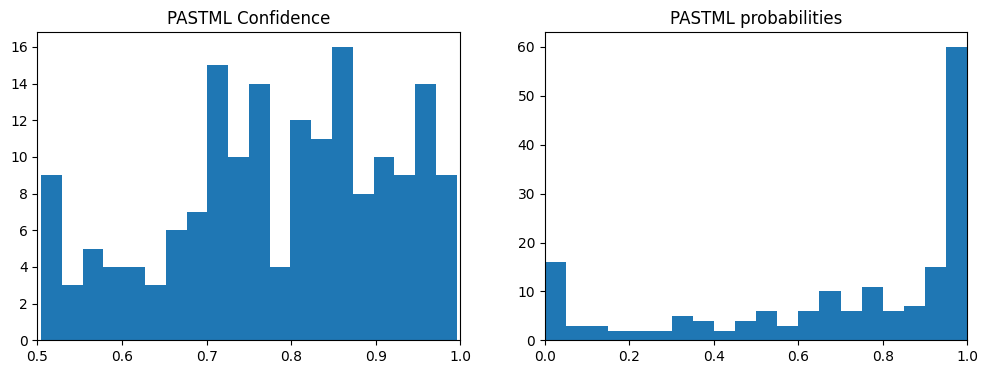

In [75]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(different["pastml_confidence"], bins=20);
plt.xlim([0.5, 1])
plt.title("PASTML Confidence");

plt.subplot(1, 2, 2)
plt.hist(different["proba_and_uncert"], bins=20);
plt.xlim([0, 1])
plt.title("PASTML probabilities");

In [67]:
different.to_csv(f"{OUTPUT_DIRECTORY}/ml_vs_pastml.csv", index=False)  

In [68]:
f"{OUTPUT_DIRECTORY}/ml_vs_pastml.csv"

'../data_aerob/outputs/phylum/ml_vs_pastml.csv'

In [45]:
# phenotype_col = "oxytolerance"

# # Map phenotype names to states
# phenotype_map = {
#     "anaerobe": 0,
#     "aerobe": 1
# }

# # Create accession -> phenotype dictionary
# phenotype_dict = (
#     merged_tab
#     .set_index("accession")[phenotype_col]
#     .map(phenotype_map)
#     .dropna()
#     .to_dict()
# )

# len(phenotype_dict.keys())

In [46]:
# # accession -> tree leaf name
# accession_to_leaf = (
#     leaves_acc_names
#     .set_index("accession")["ShortCode"]
#     .to_dict()
# )

# leaf_phenotype_dict = {
#     accession_to_leaf[accession]: phenotype
#     for accession, phenotype in phenotype_dict.items()
#     if accession in accession_to_leaf
# }

# # df_pred

# len(leaf_phenotype_dict)

In [47]:
# pastml_results = []

# for pastml_name, tipset in pastml_tipset_by_name.items():
#     if tipset not in nodename_by_tipset or pastml_name not in probs.index:
#         continue

#     matched_nodename = nodename_by_tipset[tipset]
#     p0 = probs.loc[pastml_name, "0"]
#     p1 = probs.loc[pastml_name, "1"]

#     pastml_results.append({
#         "NodeName": matched_nodename,
#         "pastml_p0": p0,
#         "pastml_p1": p1,
#         "pastml_call": "aerobe" if p1 > p0 else "anaerobe",
#         "pastml_confidence": max(p0, p1)
#     })

# pastml_df = pd.DataFrame(pastml_results)
# print(len(pastml_df), "nodes matched")

#### 5.2.  Wagner predictions

In [76]:
from Bio import Phylo

# Read the already existing tree file that we annotate with the model predictions below 
tree = Phylo.read("../ancestral_data/C65.tree", "newick")

In [77]:
phenotype_col = "oxytolerance"

# Map phenotype names to states
phenotype_map = {
    "anaerobe": 0,
    "aerobe": 1
}

# Create accession -> phenotype dictionary
phenotype_dict = (
    merged_tab
    .set_index("accession")[phenotype_col]
    .map(phenotype_map)
    .dropna()
    .to_dict()
)

len(phenotype_dict.keys())

3161

In [78]:
len(phenotype_dict)

3161

In [79]:
# accession -> tree leaf name
accession_to_leaf = (
    leaves_acc_names
    .set_index("accession")["ShortCode"]
    .to_dict()
)

leaf_phenotype_dict = {
    accession_to_leaf[accession]: phenotype
    for accession, phenotype in phenotype_dict.items()
    if accession in accession_to_leaf
}

# df_pred

len(leaf_phenotype_dict)

242

In [81]:
# All ML predicted leaves

# Map oxytolerance labels to binary values (adjust mapping if your convention differs)
oxytolerance_to_binary = {
    "aerobe": 1,
    "anaerobe": 0,
}

# Filter to rows where phylum is not None, then build the dict
#df_filtered = df_pred[df_pred["phylum"].notna()]
df_filtered = df_filtered[~df_filtered["NodeName"].astype(str).str.fullmatch(r"\d{4}")].copy()

leaf_phenotype_dict = dict(
    zip(
        df_filtered["NodeName"],
        df_filtered["oxytolerance"].map(oxytolerance_to_binary),
    )
)

print(len(leaf_phenotype_dict))
# leaf_phenotype_dict

NameError: name 'df_filtered' is not defined

In [174]:
# df_pred

In [82]:
tree_leaves = {leaf.name for leaf in tree.get_terminals()}

matched = set(leaf_phenotype_dict) & tree_leaves
not_in_tree = set(leaf_phenotype_dict) - tree_leaves

print("Phenotype annotations:", len(phenotype_dict))
print("Mapped to tree names:", len(leaf_phenotype_dict))
print("Found in tree:", len(matched))
print("Not found in tree:", len(not_in_tree))

print("Examples not found:", list(not_in_tree)[:10])

Phenotype annotations: 3161
Mapped to tree names: 242
Found in tree: 242
Not found in tree: 0
Examples not found: []


In [83]:
import copy

pruned_tree = copy.deepcopy(tree)

for leaf in pruned_tree.get_terminals():
    if leaf.name not in leaf_phenotype_dict:
        pruned_tree.prune(leaf)

print("Original leaves:", len(tree.get_terminals()))
print("Pruned leaves:", len(pruned_tree.get_terminals()))

Original leaves: 1007
Pruned leaves: 242


In [84]:
all_nodes = pruned_tree.find_clades()

In [85]:
from utils.utils_ancestral_predict import wagner_reconstruction

In [86]:
state_labels = {
    0: "anaerobe",
    1: "aerobe"
}

(
    node_annotations,
    node_confidence,
    node_probabilities,
    scores,
    parsimony_score
) = wagner_reconstruction(
    pruned_tree,
    leaf_phenotype_dict,
    state_labels=state_labels
)

parsimony_score

22.0

In [87]:
print("annotations:", len(node_annotations))
print("confidence:", len(node_confidence))
print("probabilities:", len(node_probabilities))
print("scores:", len(scores))
print("parsimony:", parsimony_score)

annotations: 483
confidence: 483
probabilities: 483
scores: 483
parsimony: 22.0


In [88]:
from utils.utils_ancestral_predict import dollo_reconstruction

(
    node_annotations_dollo, 
    node_confidence_dollo, 
    node_probabilities_dollo, 
    scores_dollo, 
    parsimony_score_dollo 
) = dollo_reconstruction(pruned_tree, leaf_phenotype_dict, state_labels=state_labels)

parsimony_score_dollo

38.0

In [89]:
def get_node_id(node):
    if node.name is not None:
        return str(node.name)
    elif node.confidence is not None:
        return str(node.confidence)
    else:
        return None

In [90]:
# Wagner preds
all_nodes = list(pruned_tree.find_clades())

wagner_annotation = {
    get_node_id(node): node_annotations[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_confidence = {
    get_node_id(node): node_confidence[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_diderm_proba = {
    get_node_id(node): node_probabilities[node][0]
    for node in all_nodes
    if get_node_id(node) is not None
}

wagner_monoderm_proba = {
    get_node_id(node): node_probabilities[node][1]
    for node in all_nodes
    if get_node_id(node) is not None
}


In [91]:
df_pred["wagner_annotation"] = (
    df_pred["NodeName"].astype(str).map(wagner_annotation)
)

df_pred["wagner_confidence"] = (
    df_pred["NodeName"].astype(str).map(wagner_confidence)
)

df_pred["wagner_diderm_proba"] = (
    df_pred["NodeName"].astype(str).map(wagner_diderm_proba)
)

df_pred["wagner_monoderm_proba"] = (
    df_pred["NodeName"].astype(str).map(wagner_monoderm_proba)
)

In [92]:
# Dollo preds
all_nodes = list(pruned_tree.find_clades())

dollo_annotation = {
    get_node_id(node): node_annotations_dollo[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

dollo_confidence = {
    get_node_id(node): node_confidence_dollo[node]
    for node in all_nodes
    if get_node_id(node) is not None
}

dollo_diderm_proba = {
    get_node_id(node): node_probabilities_dollo[node][0]
    for node in all_nodes
    if get_node_id(node) is not None
}

dollo_monoderm_proba = {
    get_node_id(node): node_probabilities_dollo[node][1]
    for node in all_nodes
    if get_node_id(node) is not None
}


In [93]:
df_pred["dollo_annotation"] = (
    df_pred["NodeName"].astype(str).map(dollo_annotation)
)

df_pred["dollo_confidence"] = (
    df_pred["NodeName"].astype(str).map(dollo_confidence)
)

df_pred["dollo_diderm_proba"] = (
    df_pred["NodeName"].astype(str).map(dollo_diderm_proba)
)

df_pred["dollo_monoderm_proba"] = (
    df_pred["NodeName"].astype(str).map(dollo_monoderm_proba)
)

In [94]:
df_pred

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,wagner_annotation,wagner_confidence,wagner_diderm_proba,wagner_monoderm_proba,dollo_annotation,dollo_confidence,dollo_diderm_proba,dollo_monoderm_proba
0,AABM5X1,anaerobe,predict,0.997830,p__AABM5-125-24,0.002170,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AABM5X2,anaerobe,predict,0.999330,p__AABM5-125-24,0.000670,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AABM5X3,anaerobe,predict,0.999578,p__AABM5-125-24,0.000422,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abys1,anaerobe,predict,0.999979,p__Abyssubacteria,0.000021,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Acid1,aerobe,predict,0.997253,p__Acidobacteriota,0.997253,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,2008,anaerobe,predict,0.990327,None,0.009673,anaerobe,0.731059,0.731059,0.268941,aerobe,1.0,0.0,1.0
2009,2009,anaerobe,predict,0.876679,None,0.123321,anaerobe,0.880797,0.880797,0.119203,aerobe,1.0,0.0,1.0
2010,2010,anaerobe,predict,0.965955,None,0.034045,anaerobe,0.880797,0.880797,0.119203,aerobe,1.0,0.0,1.0
2011,2011,anaerobe,predict,0.882038,None,0.117962,anaerobe,0.880797,0.880797,0.119203,aerobe,1.0,0.0,1.0


In [95]:
mask = df_pred['wagner_annotation'].notna() & (df_pred['oxytolerance'] != df_pred['wagner_annotation'])
disagree_nodes = df_pred.loc[mask, 'NodeName']

print(disagree_nodes.tolist())

['1494', '1604', '1647', '1712', '1827', '1831', '1860', '1864', '1919', '1923', '1933', '1935', '1988', '1993', '1995']


In [96]:
# disagree_nodes = df_pred.loc[mask, 'annot_or_predict']
# disagree_nodes

In [97]:
disagree_df = df_pred.loc[mask, ["NodeName", "oxytolerance", "wagner_annotation", "wagner_confidence"]]
print(disagree_df)
print(disagree_df["oxytolerance"].unique())
print(disagree_df["wagner_annotation"].unique())

     NodeName oxytolerance wagner_annotation  wagner_confidence
1494     1494       aerobe         Ambiguous           0.500000
1604     1604     anaerobe         Ambiguous           0.500000
1647     1647       aerobe         Ambiguous           0.731059
1712     1712     anaerobe         Ambiguous           0.731059
1827     1827     anaerobe         Ambiguous           0.500000
1831     1831     anaerobe            aerobe           0.880797
1860     1860       aerobe          anaerobe           0.500000
1864     1864       aerobe          anaerobe           0.500000
1919     1919     anaerobe         Ambiguous           0.731059
1923     1923       aerobe          anaerobe           0.500000
1933     1933     anaerobe            aerobe           0.880797
1935     1935       aerobe          anaerobe           0.731059
1988     1988     anaerobe            aerobe           0.880797
1993     1993     anaerobe         Ambiguous           0.500000
1995     1995     anaerobe         Ambig

In [98]:
mask = df_pred['dollo_annotation'].notna() & (df_pred['oxytolerance'] != df_pred['dollo_annotation'])
disagree_nodes = df_pred.loc[mask, 'NodeName']

print(disagree_nodes.tolist())

['1051', '1604', '1634', '1712', '1729', '1755', '1825', '1827', '1831', '1888', '1904', '1907', '1918', '1919', '1933', '1944', '1945', '1954', '1969', '1971', '1980', '1981', '1984', '1986', '1988', '1990', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012']


In [99]:
disagree_df = df_pred.loc[mask, ["NodeName", "oxytolerance", "dollo_annotation", "dollo_confidence"]]
print(disagree_df)
print(disagree_df["oxytolerance"].unique())
print(disagree_df["dollo_annotation"].unique())

     NodeName oxytolerance dollo_annotation  dollo_confidence
1051     1051     anaerobe           aerobe               1.0
1604     1604     anaerobe           aerobe               1.0
1634     1634     anaerobe           aerobe               1.0
1712     1712     anaerobe           aerobe               1.0
1729     1729     anaerobe           aerobe               1.0
1755     1755     anaerobe           aerobe               1.0
1825     1825     anaerobe           aerobe               1.0
1827     1827     anaerobe           aerobe               1.0
1831     1831     anaerobe           aerobe               1.0
1888     1888     anaerobe           aerobe               1.0
1904     1904     anaerobe           aerobe               1.0
1907     1907     anaerobe           aerobe               1.0
1918     1918     anaerobe           aerobe               1.0
1919     1919     anaerobe           aerobe               1.0
1933     1933     anaerobe           aerobe               1.0
1944    

#### 5.3 Phenotype prediction summary

In [193]:
# Create and save a tree file with all the model prediction labels

from Bio import Phylo
from utils.utils_ancestral_predict import process_res

# Read the already existing tree file that we annotate with the model predictions below 
tree = Phylo.read("../ancestral_data/C65.tree", "newick")

# The names of important COGs for the phenotype
cog_names = ['COG0109', 'COG1612', 'COG1014', 'COG0026', 'COG1328', 'COG1592']

for clade in tree.find_clades(order="level"):
    node_name = clade.name if clade.name is not None else str(clade.confidence)

    # Generate the model prediction comments for the tree file
    oxytol_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "oxytolerance"])
    predict_annot_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "annot_or_predict"])
    max_proba_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "max_proba"])
    max_proba_comm = str(round(float(max_proba_comm), 2)) if max_proba_comm != '' else ''
    phylum_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "phylum"])

    proba_and_uncert_comm = process_res(df_pred.loc[df_pred["NodeName"] == node_name, "proba_and_uncert"])
    proba_and_uncert_comm = str(round(float(proba_and_uncert_comm), 2)) if proba_and_uncert_comm != '' else ''

    wagner_annot_comm = process_res(
        df_pred.loc[df_pred["NodeName"] == node_name, "wagner_annotation"]
    )

    wagner_conf_comm = process_res(
        df_pred.loc[df_pred["NodeName"] == node_name, "wagner_confidence"]
    )

    
    if oxytol_comm == "aerobe":
        color = "#d62728" 
    else:
        color = "#1f77b4"  

    comment_str = f'&!color={color}, oxytol={oxytol_comm}, predict_annot={predict_annot_comm},max_proba={max_proba_comm},proba_and_uncert = {proba_and_uncert_comm}, phylum_comm = {phylum_comm},wagner_annotation={wagner_annot_comm},wagner_confidence={wagner_conf_comm}'#,{cog_name}={str(cog_count)}'

    for cog_name in cog_names:
        cog_count = int(pivot_df.loc[node_name, cog_name]) if cog_name in pivot_df.columns else 0  
        if cog_count > 1:
            cog_count = 1
        comment_str += f',{cog_name}={str(cog_count)}'

    clade.comment = comment_str
    
# Save the tree file with all annotations
filename =   f"../ancestral_data/aerob_C65_annotated_on_noisy_train_fp_{fp_rate_mean}_fn_{fn_rate_mean}_noise_type_{noise_type}_x_{x}_ancRootTable_threshold_orig.tree"#{threshold}.tree"  
Phylo.write(tree, filename, "nexus")
filename


'../ancestral_data/aerob_C65_annotated_on_noisy_train_fp_0.1_fn_0.5_noise_type_unif_x_100_ancRootTable_threshold_orig.tree'

In [195]:
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score

# Wagner

compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["wagner_annotation"].notna()) &
    (df_pred["NodeName"].astype(str).str.fullmatch(r"\d{4}"))
].copy()

# Add node ages 

def get_node_id(node):
    if node.name is not None:
        return str(node.name)
    elif node.confidence is not None:
        return str(node.confidence)
    else:
        return None

tree_height = max(
    tree.distance(tree.root, tip)
    for tip in tree.get_terminals()
)

node_ages = {
    get_node_id(node): tree_height - tree.distance(tree.root, node)
    for node in tree.find_clades()
    if get_node_id(node) is not None
}

compare_df["node_age"] = compare_df["NodeName"].astype(str).map(node_ages)


compare_df

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,wagner_annotation,wagner_confidence,wagner_diderm_proba,wagner_monoderm_proba,dollo_annotation,dollo_confidence,dollo_diderm_proba,dollo_monoderm_proba,node_age
1007,1007,anaerobe,predict,0.999250,None,0.000750,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203,816.5050
1008,1008,anaerobe,predict,0.997537,None,0.002463,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203,1711.0800
1009,1009,aerobe,predict,0.984559,None,0.984559,aerobe,0.880797,0.119203,0.880797,aerobe,1.000000,0.000000,1.000000,1471.7750
1010,1010,anaerobe,predict,0.986886,None,0.013114,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203,1556.9100
1011,1011,aerobe,predict,0.846551,None,0.846551,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203,780.6730
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,2008,anaerobe,predict,0.994729,None,0.005271,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000,4068.4644
2009,2009,anaerobe,predict,0.882849,None,0.117151,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000,4098.6430
2010,2010,anaerobe,predict,0.974600,None,0.025400,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000,4180.1994
2011,2011,anaerobe,predict,0.907835,None,0.092165,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000,4299.2734


In [196]:
disagree = compare_df[
    compare_df["oxytolerance"] != compare_df["wagner_annotation"]
].copy()

mean_age = disagree["node_age"].mean()
std_age = disagree["node_age"].std()

print("Number of disagreements:", len(disagree))
print("Percent of disagreements:", len(disagree)/len(compare_df))
print("Mean node age:", mean_age)
print("SD node age:", std_age)

Number of disagreements: 74
Percent of disagreements: 0.07429718875502007
Mean node age: 1863.015164864865
SD node age: 774.8712078924274


In [197]:
compare_df.to_csv(f"{OUTPUT_DIRECTORY}/ml_wagner_dollo_on_full_tree.csv", index=False)  

In [198]:
cm = confusion_matrix(
    compare_df["oxytolerance"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe", "Ambiguous"]
)

print("Number of ancestral nodes:", len(compare_df))
print(cm)

Number of ancestral nodes: 996
[[542  23  24]
 [ 15 380  12]
 [  0   0   0]]


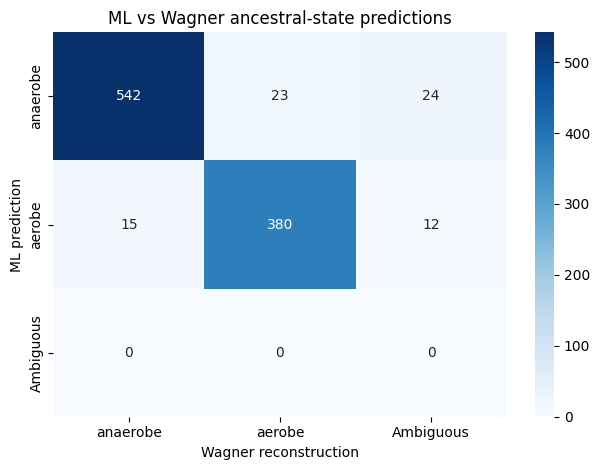

In [199]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = ["anaerobe", "aerobe", "Ambiguous"]

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)

plt.xlabel("Wagner reconstruction")
plt.ylabel("ML prediction")
plt.title("ML vs Wagner ancestral-state predictions")
plt.tight_layout()
plt.show()

In [200]:
n_total = len(compare_df)
n_agree = (compare_df["oxytolerance"] == compare_df["wagner_annotation"]).sum()
n_ambiguous = (compare_df["wagner_annotation"] == "Ambiguous").sum()
n_hard_disagree = n_total - n_agree - n_ambiguous

print(f"Total compared nodes: {n_total}")
print(f"Agreement (exact match): {n_agree} ({n_agree/n_total:.1%})")
print(f"Wagner ambiguous: {n_ambiguous} ({n_ambiguous/n_total:.1%})")
print(f"Hard disagreement: {n_hard_disagree} ({n_hard_disagree/n_total:.1%})")

# agreement rate among nodes where Wagner actually committed to a state
resolved_df = compare_df[compare_df["wagner_annotation"] != "Ambiguous"]
resolved_agreement = (resolved_df["oxytolerance"] == resolved_df["wagner_annotation"]).mean()
print(f"Agreement among Wagner-resolved nodes: {resolved_agreement:.1%}")

Total compared nodes: 996
Agreement (exact match): 922 (92.6%)
Wagner ambiguous: 36 (3.6%)
Hard disagreement: 38 (3.8%)
Agreement among Wagner-resolved nodes: 96.0%


In [201]:
1751-36


1715

In [202]:
# compare_df

In [205]:
from sklearn.metrics import matthews_corrcoef

# Only predicted ancestral nodes
compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["wagner_annotation"].notna()) &
    (df_pred["NodeName"].astype(str).str.fullmatch(r"\d{4}"))
].copy()

# Convert labels to 0/1
state_labels = {
    "anaerobe": 0,
    "aerobe": 1
}

y_ml = compare_df["oxytolerance"].map(state_labels)
y_wagner = compare_df["wagner_annotation"].map(state_labels)

# Remove any rows with unmapped labels
valid = y_ml.notna() & y_wagner.notna()

mcc = matthews_corrcoef(
    y_ml[valid],
    y_wagner[valid]
)

print("MCC:", mcc)
print("Number of ancestral nodes:", valid.sum())

MCC: 0.918653854714906
Number of ancestral nodes: 960


In [206]:
kappa = cohen_kappa_score(
    compare_df["oxytolerance"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe"]
)

print(f"Cohen's κ: {kappa:.3f}")

Cohen's κ: 0.919


In [207]:
kappa = cohen_kappa_score(
    compare_df["oxytolerance"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe", "Ambiguous"]
)

print(f"Cohen's κ: {kappa:.3f}")

Cohen's κ: 0.853


In [208]:
from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score

# Dollo

compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["dollo_annotation"].notna()) &
    (df_pred["NodeName"].astype(str).str.fullmatch(r"\d{4}"))
].copy()

compare_df

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,wagner_annotation,wagner_confidence,wagner_diderm_proba,wagner_monoderm_proba,dollo_annotation,dollo_confidence,dollo_diderm_proba,dollo_monoderm_proba
1007,1007,anaerobe,predict,0.999250,None,0.000750,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
1008,1008,anaerobe,predict,0.997537,None,0.002463,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
1009,1009,aerobe,predict,0.984559,None,0.984559,aerobe,0.880797,0.119203,0.880797,aerobe,1.000000,0.000000,1.000000
1010,1010,anaerobe,predict,0.986886,None,0.013114,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
1011,1011,aerobe,predict,0.846551,None,0.846551,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,2008,anaerobe,predict,0.994729,None,0.005271,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000
2009,2009,anaerobe,predict,0.882849,None,0.117151,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000
2010,2010,anaerobe,predict,0.974600,None,0.025400,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000
2011,2011,anaerobe,predict,0.907835,None,0.092165,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000


In [209]:
cm = confusion_matrix(
    compare_df["oxytolerance"],
    compare_df["dollo_annotation"],
    labels=["anaerobe", "aerobe"]
)

print("Number of ancestral nodes:", len(compare_df))
print(cm)

Number of ancestral nodes: 996
[[390 199]
 [  2 405]]


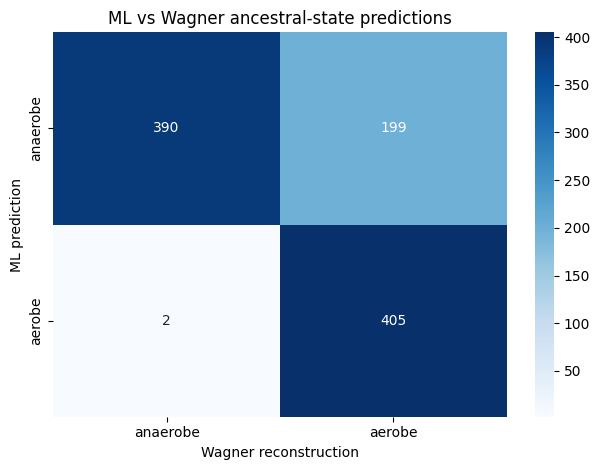

In [210]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = ["anaerobe", "aerobe"]

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)

plt.xlabel("Wagner reconstruction")
plt.ylabel("ML prediction")
plt.title("ML vs Wagner ancestral-state predictions")
plt.tight_layout()
plt.show()

In [211]:
n_total = len(compare_df)
n_agree = (compare_df["oxytolerance"] == compare_df["dollo_annotation"]).sum()
n_ambiguous = (compare_df["dollo_annotation"] == "Ambiguous").sum()
n_hard_disagree = n_total - n_agree - n_ambiguous

print(f"Total compared nodes: {n_total}")
print(f"Agreement (exact match): {n_agree} ({n_agree/n_total:.1%})")
print(f"Dollo ambiguous: {n_ambiguous} ({n_ambiguous/n_total:.1%})")
print(f"Hard disagreement: {n_hard_disagree} ({n_hard_disagree/n_total:.1%})")

# agreement rate among nodes where Wagner actually committed to a state
resolved_df = compare_df[compare_df["dollo_annotation"] != "Ambiguous"]
resolved_agreement = (resolved_df["oxytolerance"] == resolved_df["dollo_annotation"]).mean()
print(f"Agreement among Dollo-resolved nodes: {resolved_agreement:.1%}")

Total compared nodes: 996
Agreement (exact match): 795 (79.8%)
Dollo ambiguous: 0 (0.0%)
Hard disagreement: 201 (20.2%)
Agreement among Dollo-resolved nodes: 79.8%


In [212]:
from sklearn.metrics import matthews_corrcoef

# Only predicted ancestral nodes
compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["dollo_annotation"].notna()) &
    (df_pred["NodeName"].astype(str).str.fullmatch(r"\d{4}"))
].copy()

# Convert labels to 0/1
state_labels = {
    "anaerobe": 0,
    "aerobe": 1
}

y_ml = compare_df["oxytolerance"].map(state_labels)
y_wagner = compare_df["dollo_annotation"].map(state_labels)

# Remove any rows with unmapped labels
valid = y_ml.notna() & y_wagner.notna()

mcc = matthews_corrcoef(
    y_ml[valid],
    y_wagner[valid]
)

print("MCC:", mcc)
print("Number of ancestral nodes:", valid.sum())

MCC: 0.6613137699828414
Number of ancestral nodes: 996


In [213]:
kappa = cohen_kappa_score(
    compare_df["oxytolerance"],
    compare_df["dollo_annotation"],
    labels=["anaerobe", "aerobe"]
)

print(f"Cohen's κ: {kappa:.3f}")

Cohen's κ: 0.611


In [214]:
# Dollo to Wagner 

from sklearn.metrics import confusion_matrix, accuracy_score, cohen_kappa_score


compare_df = df_pred[
    (df_pred["annot_or_predict"] == "predict") &
    (df_pred["dollo_annotation"].notna()) &
    (df_pred["NodeName"].astype(str).str.fullmatch(r"\d{4}"))
].copy()

compare_df

,NodeName,oxytolerance,annot_or_predict,max_proba,phylum,proba_and_uncert,wagner_annotation,wagner_confidence,wagner_diderm_proba,wagner_monoderm_proba,dollo_annotation,dollo_confidence,dollo_diderm_proba,dollo_monoderm_proba
1007,1007,anaerobe,predict,0.999250,None,0.000750,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
1008,1008,anaerobe,predict,0.997537,None,0.002463,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
1009,1009,aerobe,predict,0.984559,None,0.984559,aerobe,0.880797,0.119203,0.880797,aerobe,1.000000,0.000000,1.000000
1010,1010,anaerobe,predict,0.986886,None,0.013114,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
1011,1011,aerobe,predict,0.846551,None,0.846551,anaerobe,0.880797,0.880797,0.119203,anaerobe,0.880797,0.880797,0.119203
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2008,2008,anaerobe,predict,0.994729,None,0.005271,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000
2009,2009,anaerobe,predict,0.882849,None,0.117151,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000
2010,2010,anaerobe,predict,0.974600,None,0.025400,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000
2011,2011,anaerobe,predict,0.907835,None,0.092165,anaerobe,0.880797,0.880797,0.119203,aerobe,1.000000,0.000000,1.000000


In [215]:
cm = confusion_matrix(
    compare_df["dollo_annotation"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe", "Ambiguous"]
)

print("Number of ancestral nodes:", len(compare_df))
print(cm)

Number of ancestral nodes: 996
[[392   0   0]
 [165 403  36]
 [  0   0   0]]


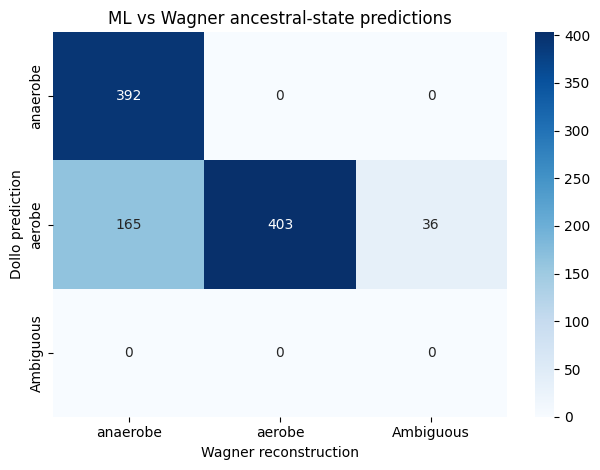

In [216]:
import seaborn as sns
import matplotlib.pyplot as plt

labels = ["anaerobe", "aerobe", "Ambiguous"]

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)

plt.xlabel("Wagner reconstruction")
plt.ylabel("Dollo prediction")
plt.title("ML vs Wagner ancestral-state predictions")
plt.tight_layout()
plt.show()

In [217]:
n_total = len(compare_df)
n_agree = (compare_df["dollo_annotation"] == compare_df["wagner_annotation"]).sum()
n_ambiguous = (compare_df["wagner_annotation"] == "Ambiguous").sum()
n_hard_disagree = n_total - n_agree - n_ambiguous

print(f"Total compared nodes: {n_total}")
print(f"Agreement (exact match): {n_agree} ({n_agree/n_total:.1%})")
print(f"Wagner ambiguous: {n_ambiguous} ({n_ambiguous/n_total:.1%})")
print(f"Hard disagreement: {n_hard_disagree} ({n_hard_disagree/n_total:.1%})")

# agreement rate among nodes where Wagner actually committed to a state
resolved_df = compare_df[compare_df["wagner_annotation"] != "Ambiguous"]
resolved_agreement = (resolved_df["dollo_annotation"] == resolved_df["wagner_annotation"]).mean()
print(f"Agreement among Wagner-resolved nodes: {resolved_agreement:.1%}")

Total compared nodes: 996
Agreement (exact match): 795 (79.8%)
Wagner ambiguous: 36 (3.6%)
Hard disagreement: 165 (16.6%)
Agreement among Wagner-resolved nodes: 82.8%


In [218]:
kappa = cohen_kappa_score(
    compare_df["dollo_annotation"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe"]
)

print(f"Cohen's κ: {kappa:.3f}")

Cohen's κ: 0.666


In [219]:
kappa = cohen_kappa_score(
    compare_df["dollo_annotation"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe", "Ambiguous"]
)

print(f"Cohen's κ: {kappa:.3f}")

Cohen's κ: 0.622


In [ ]:
compare_df.to_csv(f"{OUTPUT_DIRECTORY}/ml_wagner_dollo_on_full_tree.csv", index=False)  

In [221]:
df_full = pd.read_csv(f"{OUTPUT_DIRECTORY}/ml_wagner_dollo_on_full_tree.csv")  #compare_df.to_csv(f"{OUTPUT_DIRECTORY}/ml_wagner_dollo_on_full_tree.csv", index=False)  
df_pruned = pd.read_csv(f"{OUTPUT_DIRECTORY}/ml_wagner_dollo_on_pruned_tree.csv")  #compare_df.to_csv(f"{OUTPUT_DIRECTORY}/ml_wagner_dollo_on_full_tree.csv", index=False)  

In [225]:
node_names_full = set(df_full["NodeName"])
node_names_pruned = set(df_pruned["NodeName"])

print(f"full len = {len(node_names_full)}")
print(f"pruned len = {len(node_names_pruned)}")

full len = 996
pruned len = 241


In [226]:
node_names_pruned - node_names_full

set()

In [47]:
kappa = cohen_kappa_score(
    compare_df["oxytolerance"],
    compare_df["wagner_annotation"],
    labels=["anaerobe", "aerobe"]
)

print(f"Cohen's κ: {kappa:.3f}")

Cohen's κ: 0.944


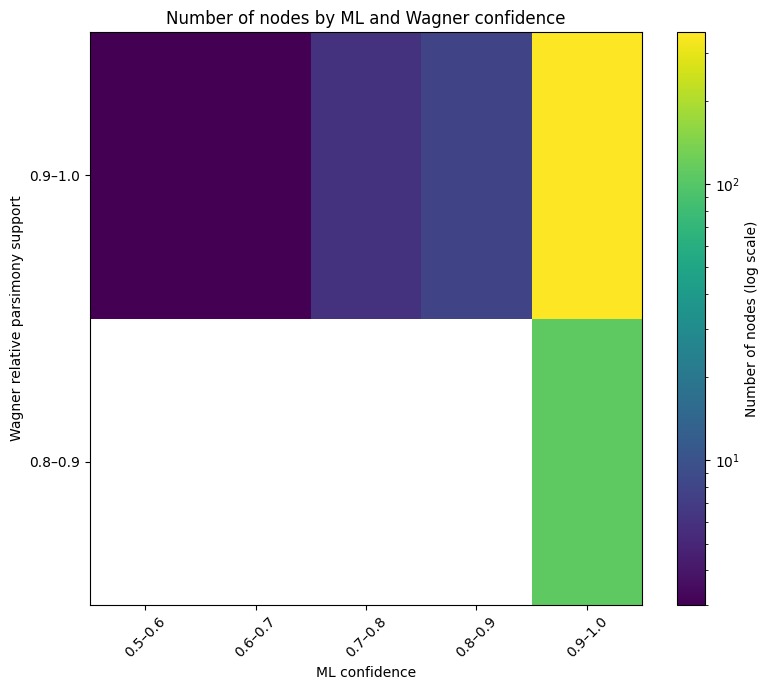

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plot_df = df_pred.dropna(
    subset=["max_proba", "wagner_confidence"]
).copy()

bins = [0, 0.1, 0.2, 0.3, 0.4, 0.5,
        0.6, 0.7, 0.8, 0.9, 1.0]

plot_df["ML_bin"] = pd.cut(
    plot_df["max_proba"], bins=bins, include_lowest=True
)

plot_df["Wagner_bin"] = pd.cut(
    plot_df["wagner_confidence"], bins=bins, include_lowest=True
)

counts = pd.crosstab(
    plot_df["Wagner_bin"],
    plot_df["ML_bin"]
)

# Replace zeros with NaN so they are not included in log scaling
counts_log = counts.replace(0, float("nan"))

plt.figure(figsize=(8, 7))

plt.imshow(
    counts_log,
    origin="lower",
    aspect="auto",
    norm=LogNorm(
        vmin=counts_log.min().min(),
        vmax=counts_log.max().max()
    )
)

plt.xticks(
    range(len(counts.columns)),
    [f"{b.left:.1f}–{b.right:.1f}" for b in counts.columns],
    rotation=45
)

plt.yticks(
    range(len(counts.index)),
    [f"{b.left:.1f}–{b.right:.1f}" for b in counts.index]
)

plt.xlabel("ML confidence")
plt.ylabel("Wagner relative parsimony support")
plt.title("Number of nodes by ML and Wagner confidence")

cbar = plt.colorbar()
cbar.set_label("Number of nodes (log scale)")

plt.tight_layout()
plt.show()